In [1]:
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os
import pickle

In [2]:
import helper_functions as hf

In [3]:
plt.rcParams.update({'font.size': 14})

## Figure 1 (kinetic model)

In [4]:
!mkdir figures

A subdirectory or file figures already exists.


### A (kinetic model)

Rendered in latex

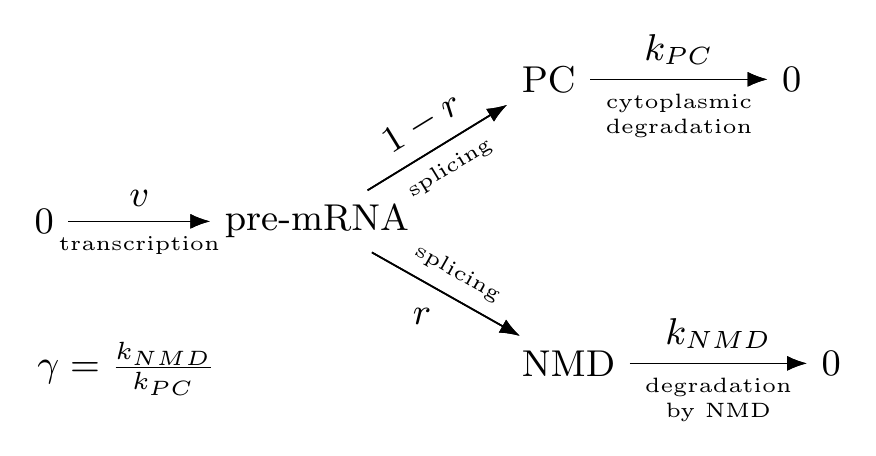

In [5]:
import subprocess
from pathlib import Path
from IPython.display import display, IFrame

tex_source = r"""
\documentclass[tikz,border=5pt]{standalone}
\usepackage{amsmath}
\usepackage{tikz}
\usetikzlibrary{positioning,arrows.meta,calc}

\begin{document}

\begin{tikzpicture}[
%    node distance=1cm and 0.5cm,
    node distance=0.5cm and 1.5cm,
    every node/.style={font=\small},
    >=Latex
]

\node (A) at (0,0) {0};
\node[right = 1.2cm of A] (B) {pre-mRNA};
\node[above right = 1cm of B] (C) {PC};
\node[below right = 1cm of B] (D) {NMD};
%\node[right = 1cm of C] (E) {0};
%\node[right = 1cm of D] (F) {0};
\node[right=of C] (E) {0};
\node[right=of D] (F) {0};



%\node (G) [below = of A] at ($(A) + (0.5, 0.5)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};
%\node (G) [below = of A] at ($(A) + (0.7, 0)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};
\node (G) [below = of A] at ($(A) + (0.7, -0.4)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};

\draw[->] (A) -- node[above] {$v$} (B);
\draw[->] (B) -- node[sloped, above] {$1-r$} (C);
\draw[->] (B) -- node[below left] {$r$} (D);
\draw[->] (C) -- node[above] {$k_{PC}$} (E);
\draw[->] (D) -- node[above] {$k_{NMD}$} (F);


\draw[->] (A) -- node[below, align=center, font=\tiny] {transcription} (B);
\draw[->] (B) -- node[sloped, below, align=center, font=\tiny] {splicing} (C);
\draw[->] (B) -- node[sloped, above, align=center, font=\tiny] {splicing} (D);
\draw[->] (C) -- node[below, align=center, font=\tiny] {cytoplasmic\\degradation} (E);
\draw[->] (D) -- node[below, align=center, font=\tiny] {degradation\\by NMD} (F);


%transcript production, alternative splicing, cytoplasmic degradation, and NMD-mediated removal


\end{tikzpicture}

\end{document}
"""

tex_path = Path('./figures/scheme.tex')

tex_path.write_text(tex_source, encoding="utf-8")

result = subprocess.run(
    [
        "pdflatex",
        "-interaction=nonstopmode",
        "-halt-on-error",
        tex_path.name
    ],
    cwd=tex_path.parent,
    capture_output=True,
    text=True
)

if result.returncode==0:

    from pdf2image import convert_from_path
    from IPython.display import display
    
    pages = convert_from_path("./figures/scheme.pdf", dpi=300)
    
    display(pages[0])
else:
    print(result.stderr)

### B (theoretical r = f(psi,gamma))

(np.float64(-0.05), np.float64(1.05), np.float64(-0.05), np.float64(1.05))

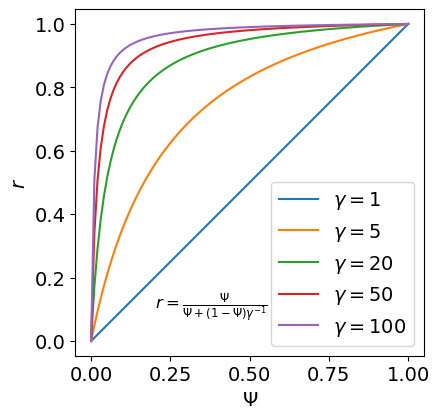

In [6]:
f,ax = plt.subplots(figsize=(4.5,4.5))
psi = np.linspace(0,1,100)
for gamma in [1,5,20,50,100]:
    r = hf.psi2r(psi,gamma)
    ax.plot(psi,r,label=f'$\gamma={gamma}$')
ax.legend()
ax.set_xlabel('$\Psi$')
ax.set_ylabel('$r$')
ax.text(0.2,0.1,r'$r = \frac{\Psi}{\Psi + (1-\Psi)\gamma^{-1}}$',fontsize=12)
ax.axis('equal')

In [7]:
f.savefig('./figures/r_from_psi_theory.pdf',bbox_inches='tight')

In [8]:
from pypdf import PdfReader, PdfWriter, PageObject

def merge_pdfs(pdf1, pdf2, out_pdf="merged.pdf"):
    reader1 = PdfReader(pdf1)
    reader2 = PdfReader(pdf2)

    # Берем первые страницы обоих документов
    page1 = reader1.pages[0]
    page2 = reader2.pages[0]

    # 1. Находим целевую (максимальную) высоту
    h1 = float(page1.mediabox.height)
    h2 = float(page2.mediabox.height)
    target_height = max(h1, h2)

    # 2. Масштабируем страницы по высоте с сохранением пропорций
    scale1 = target_height / h1
    page1.scale_by(scale1)
    
    scale2 = target_height / h2
    page2.scale_by(scale2)

    # 3. Получаем новую ширину страниц после масштабирования
    w1_new = float(page1.mediabox.width)
    w2_new = float(page2.mediabox.width)

    # Вычисляем итоговые размеры общего листа
    total_width = w1_new + w2_new

    # 4. Создаем пустой холст нужного размера
    combined_page = PageObject.create_blank_page(width=total_width, height=target_height)

    # 5. Размещаем страницы: левую без смещения, правую — со смещением по оси X
    combined_page.merge_page(page1)
    combined_page.merge_translated_page(page2, tx=w1_new, ty=0)

    # 6. Записываем результат
    writer = PdfWriter()
    writer.add_page(combined_page)

    with open(out_pdf, "wb") as f:
        writer.write(f)

    return out_pdf


In [9]:
merge_pdfs('./figures/scheme.pdf', './figures/r_from_psi_theory.pdf', out_pdf="./figures/Fig1.pdf")

'./figures/Fig1.pdf'

In [10]:
convert_from_path("./figures/Fig1.pdf", dpi=300)

from IPython.display import IFrame

# Укажите путь к созданному файлу и желаемый размер окна просмотра
pdf_path = "./figures/Fig1.pdf"
IFrame(pdf_path, width="100%", height="400px")

## Figure 2

In [11]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
nmdpsi = nmdpsi[(nmdpsi.ctrl_psi!=0)&(nmdpsi.exp_psi!=0)]
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [12]:
dkd = nmdpsi[nmdpsi.experiment=='HeLa dKD']

In [13]:
from importlib import reload
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\helper_functions.py'>

In [14]:
cols = ['set1','set2','set3']
names = ['VAL', 'PE+EE', 'ALL']
funcs = ['linear','nonlinear',"f'(0)"]

In [15]:
%%time
NITER = 50
resdf2 = []
for key,col in zip(names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    res = []
    for _ in range(NITER):
        tmp2 = tmp.sample(frac=0.5,replace=True)
        gammas = hf.get_gamma(tmp2,linear_thr=0.01,deriv0_thr=0.05,plot=False,funcs=funcs)
        res.append(pd.Series(gammas))
    res = pd.concat(res).reset_index()
    res.columns = ['method','gamma']
    res['sets'] = key
    resdf2.append(res)
resdf2 = pd.concat(resdf2) 

CPU times: total: 4.48 s
Wall time: 4.49 s


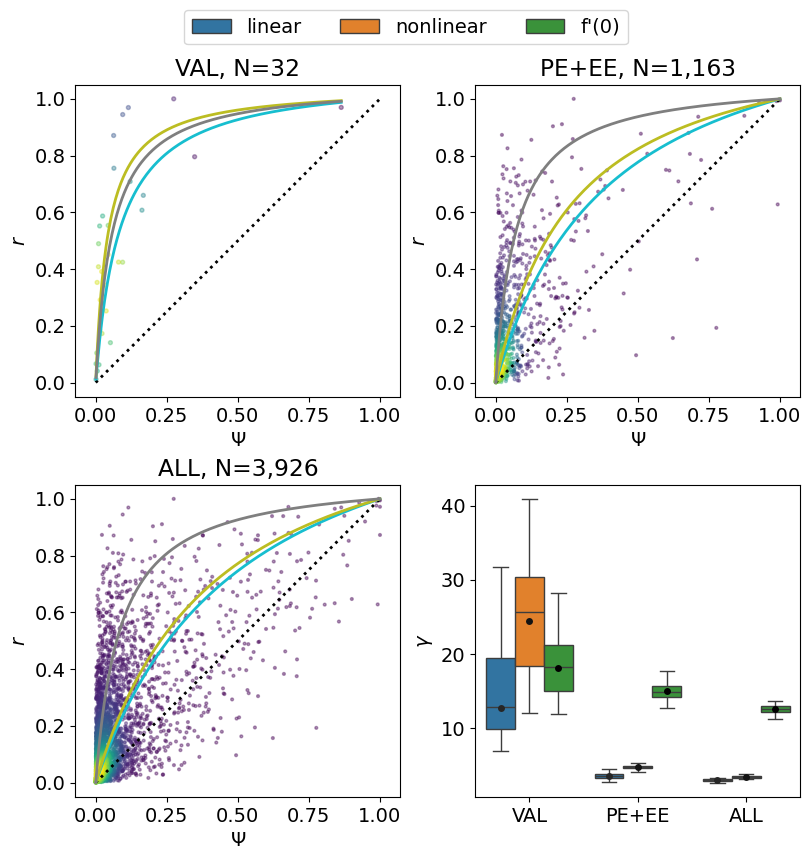

In [16]:
f, axes = plt.subplot_mosaic(
    """
    AB
    CD
    """,
    layout="constrained",
    figsize=(8,8),
    width_ratios=(1,1)
)

axes["B"].sharey(axes["A"])
axes["C"].sharey(axes["A"])


full_data = []
for (axname,ax),key,col in zip(axes.items(),names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    z,idx = hf.plot2d(tmp.ctrl_psi,tmp.exp_psi)
    ax.scatter(tmp.ctrl_psi.iloc[idx],tmp.exp_psi.iloc[idx],c=z[idx],s=8 if col=='set1' else 4 ,alpha=0.4)
    ax.plot([0,1],[0,1],lw=2,ls=':',c='black')
    #t = f'{key}, N={len(tmp)}\n{int(100*np.mean((tmp.exp_psi-tmp.ctrl_psi)>0))}%>0'
    t = f'{key}, N={len(tmp):,}'
    resd,_ = hf.get_gamma(tmp,ax=ax,linear_thr=0.01,funcs=funcs)
    resd = pd.Series(resd)
    resd.name = key
    full_data.append(resd)
    ax.set_title(t)
    #ax.legend(loc='lower center',bbox_to_anchor=(0.5,1.1))
    ax.get_legend().remove()
    ax.axis('equal')
    ax.set_xlabel(r'$\Psi$')
    ax.set_ylabel(r'$r$')

ax = axes['D']

full_data = pd.concat(full_data,axis=1)
full_data['method'] = full_data.index
full_data = full_data.melt(id_vars='method',var_name='sets',value_name='gamma')

sns.boxplot(data=resdf2,y='gamma',hue='method',x='sets',ax=ax,showfliers=False)
handles, labels = ax.get_legend_handles_labels()
f.legend(handles, labels, loc='lower center',bbox_to_anchor=(0.5,1),ncol=3)

sns.stripplot(data=full_data,y='gamma',hue='method',x='sets',ax=ax, dodge=True,palette='dark:black')
ax.set_ylabel('$\gamma$')
ax.set_xlabel(None)
ax.get_legend().remove()
#ax.set_yscale('log')

In [17]:
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\helper_functions.py'>

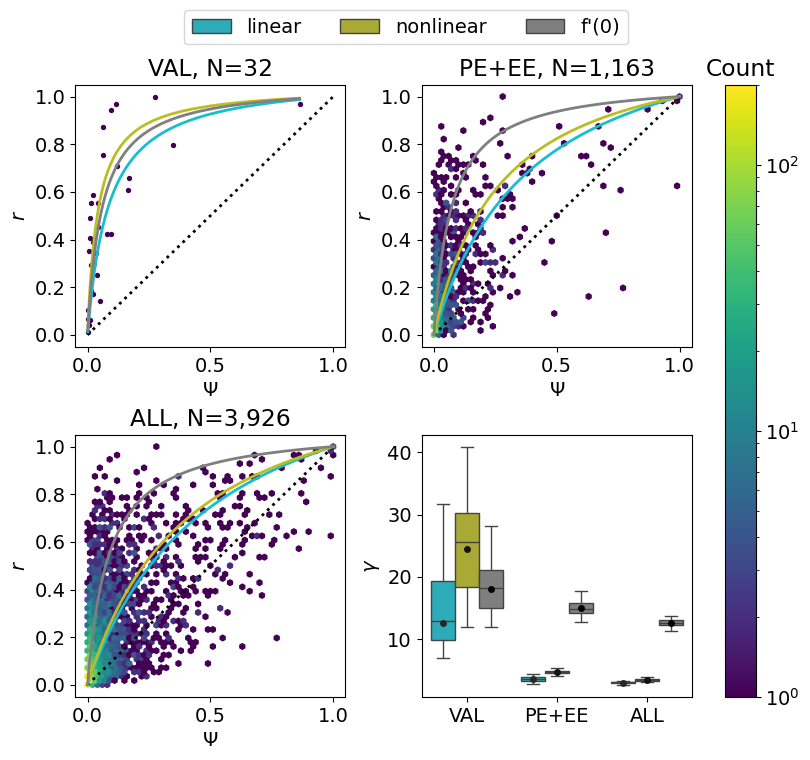

In [18]:
from matplotlib.colors import LogNorm
f, axes = plt.subplot_mosaic(
    """
    AB
    CD
    """,
    layout="constrained",
    figsize=(8,7),
    width_ratios=(1,1)
)

axes["B"].sharey(axes["A"])
axes["C"].sharey(axes["A"])

cmap = plt.get_cmap("tab10_r")
colors = cmap.colors

full_data = []
for (axname,ax),key,col in zip(axes.items(),names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    #z,idx = hf.plot2d(tmp.ctrl_psi,tmp.exp_psi)
    #ax.scatter(tmp.ctrl_psi.iloc[idx],tmp.exp_psi.iloc[idx],c=z[idx],s=8 if col=='set1' else 4 ,alpha=0.4)

    if key=='VAL':
        ax.scatter(tmp.ctrl_psi,tmp.exp_psi,s=8,color=plt.get_cmap('viridis')(0))
    else:
        
        hb = ax.hexbin(
            tmp.ctrl_psi,
            tmp.exp_psi,
            gridsize=50,
            mincnt=1,
            cmap="viridis",
            norm=LogNorm(vmin=1,vmax=200),
        )
    
    ax.plot([0,1],[0,1],lw=2,ls=':',c='black')
    #t = f'{key}, N={len(tmp)}\n{int(100*np.mean((tmp.exp_psi-tmp.ctrl_psi)>0))}%>0'
    t = f'{key}, N={len(tmp):,}'
    resd,_ = hf.get_gamma(tmp,ax=ax,linear_thr=0.01,funcs=funcs,cmap=colors)
    resd = pd.Series(resd)
    resd.name = key
    full_data.append(resd)
    ax.set_title(t)
    #ax.legend(loc='lower center',bbox_to_anchor=(0.5,1.1))
    ax.get_legend().remove()
    #ax.axis('equal')
    ax.set_xlabel(r'$\Psi$')
    ax.set_ylabel(r'$r$')

f.colorbar(hb,ax=list(axes.values()),fraction=0.05)
f.axes[-1].set_title('Count')
ax = axes['D']

full_data = pd.concat(full_data,axis=1)
full_data['method'] = full_data.index
full_data = full_data.melt(id_vars='method',var_name='sets',value_name='gamma')

sns.boxplot(data=resdf2,y='gamma',hue='method',x='sets',ax=ax,showfliers=False,palette=colors[:3])
handles, labels = ax.get_legend_handles_labels()
f.legend(handles, labels, loc='lower center',bbox_to_anchor=(0.5,1),ncol=3)

sns.stripplot(data=full_data,y='gamma',hue='method',x='sets',ax=ax, dodge=True,palette='dark:black')
ax.set_ylabel('$\gamma$')
ax.set_xlabel(None)
ax.get_legend().remove()
#ax.set_yscale('log')

In [19]:
f.savefig('./figures/Fig2.pdf',bbox_inches='tight')

## Figure 3

In [20]:
import mm
from importlib import reload
reload(mm)
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\helper_functions.py'>

In [21]:
use = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
ase = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t')

use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)]
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)]

In [22]:
def plot_dataset(exper,ctrl,ax=None,dropzeros=False, plot_borders=True, **kwargs):
    #tau=1, lambda_pi=0, lambda_sigma=0, n_init=10
    if ax is None:
        f,ax = plt.subplots()
    
    if dropzeros:
        exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)].copy()
        ctrl =  ctrl[(ctrl.ctrl_psi!=0)&(ctrl.exp_psi!=0)].copy()
    
    if (ctrl.shape[0]==0) or (exper.shape[0]==0):
        print(f'no data for {key}')
        return

    res,params,prob,other,results = mm.get_params_mixture(exper,ctrl,**kwargs)
    if res:
        mm.plot_model(exper,params,prob,ax=ax)
        print('prob',np.mean(prob>0.5))
    
        a0_hat, a1_hat, pi_hat, a_r_hat, b_r_hat, c_r_hat, a_nr_hat, b_nr_hat, c_nr_hat = params
        y = np.linspace(0,1,100)

        if plot_borders:
    
            sigma_r = mm.heteroskedastic_sigma(y, a_r_hat, b_r_hat, c_r_hat)
            sigma_nr = mm.heteroskedastic_sigma(y, a_nr_hat, b_nr_hat, c_nr_hat)
            sigma_r = np.maximum(sigma_r, 1e-3)
            sigma_nr = np.maximum(sigma_nr, 1e-3)
            curve_nr = mm.r2psi(y,a0_hat)
            curve_r = mm.r2psi(y,a1_hat)
    
            upper,lower = curve_r+sigma_r,curve_r-sigma_r
            upper,lower = np.clip(upper,0,1),np.clip(lower,0,1)
            ax.fill_betweenx(y,lower,upper,color='lightgrey',alpha=0.5)
            ax.plot(upper,y,c='grey',ls=':')
            ax.plot(lower,y,c='grey',ls=':')
            
            upper,lower = curve_nr+sigma_nr,curve_nr-sigma_nr
            upper,lower = np.clip(upper,0,1),np.clip(lower,0,1)
            ax.fill_betweenx(y,lower,upper,color='lightgrey',alpha=0.5)
            ax.plot(upper,y,c='grey',ls=':')
            ax.plot(lower,y,c='grey',ls=':')
    else:
        print(f'Model failed: {key}')
    return res,params,prob,other,results

### Mixture model plots for 3 sets of USEs in HeLa dKD

prob 0.96875


prob 0.7583834909716252


prob 0.6912888436067244
CPU times: total: 41.1 s
Wall time: 41.1 s


Text(0.02, 0.5, '$r$')

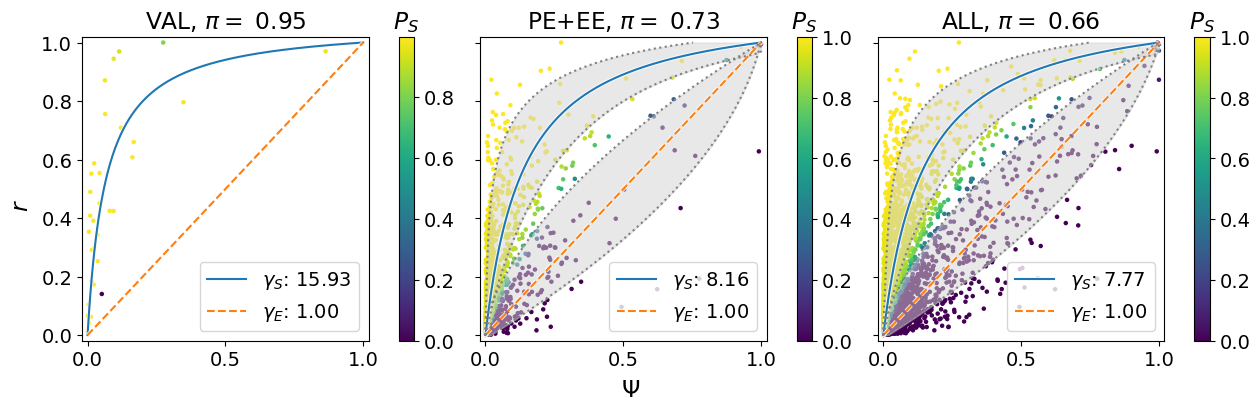

In [23]:
%%time
key = 'HeLa dKD'
cols = ['set1','set2','set3']
names = ['VAL', 'PE+EE', 'ALL']
#inits = [30,20,1]
inits = [30,30,30]

f,axes = plt.subplots(1,3,figsize=(12.5,4),constrained_layout=True,sharey=True)
for name,col,n_init,ax in zip(names,cols,inits,axes):

    exper = sets[sets[col]==1][['src','event_id']].merge(use) if col !='set0' else use.copy()
    exper = exper[exper.experiment==key].copy()
    ctrl = ase[ase.experiment==key].copy()

    plot_borders = False if name=='VAL' else True
    plot_dataset(exper,ctrl,n_init=n_init,ax=ax,plot_borders=plot_borders)
    t = ax.get_title()
    ax.set_title(f'{name}, {t}')
    ax.set_xlim(-0.02,1.02)
    ax.set_ylim(-0.02,1.02)
    
    xlab = ax.get_xlabel()
    ylab = ax.get_ylabel()
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    #ax.axis('equal')
f.supxlabel(xlab)
f.supylabel(ylab)

In [24]:
#f.axes[3]._colorbar.remove()
ax = f.axes[0]
scatter = ax.collections[0]
scatter.set_clim(0, 1)

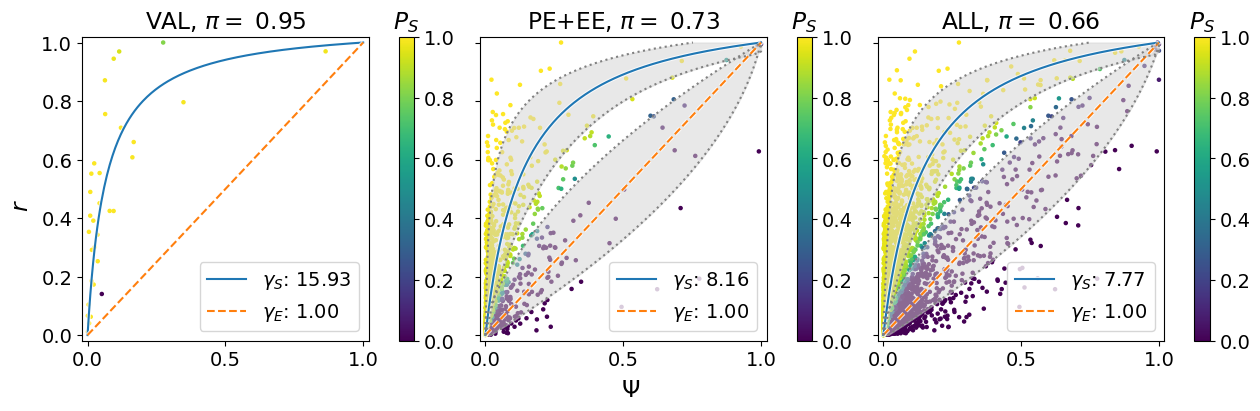

In [25]:
f

In [26]:
f.savefig('./figures/Fig3_mm_scatters.pdf',bbox_inches='tight')

In [27]:
use.experiment.unique()

array(['A549 nucl/cyto', 'H1 nucl/cyto', 'HepG2 nucl/cyto',
       'IMR-90 nucl/cyto', 'K562 nucl/cyto', 'GM12878 nucl/cyto',
       'HT1080 nucl/cyto', 'HeLa-S3 nucl/cyto', 'MCF-7 nucl/cyto',
       'SK-N-DZ nucl/cyto', 'SK-N-SH nucl/cyto',
       'vein umbilical of cell endothelial nucl/cyto',
       'keratinocyte nucl/cyto', 'NCI-H460 nucl/cyto',
       'SK-MEL-5 nucl/cyto', 'HCT116 UPF1 KD', 'HeLa CHX', 'HeLa SMG6 KD',
       'HeLa SMG7 KD', 'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

### Other datasets (mm plots, stability of $\gamma_R$ and consistency between datasets)

<a id="sf3"></a>

#### Bootstrapping

In [28]:
good_data = ['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD', 'HCT116 UPF1 KD', 'HepG2 nucl/cyto', 'K562 nucl/cyto']
tmp = use[(use.exp_psi!=0)&(use.ctrl_psi!=0)&(use.experiment.isin(good_data))]
datasets = {key1: group for key1, group in tmp.groupby('experiment')}
kwargs = [{'ctrl':ase[(ase.experiment==key)&(ase.exp_psi!=0)&(ase.ctrl_psi!=0)],'n_init':10} for key in datasets]

In [29]:
'" "'.join(good_data)

'HeLa CHX" "HeLa SMG6 KD" "HeLa UPF1 KD" "HeLa dKD" "HCT116 UPF1 KD" "HepG2 nucl/cyto" "K562 nucl/cyto'

In [30]:
{key:len(value) for key,value in datasets.items()}

{'HCT116 UPF1 KD': 4030,
 'HeLa CHX': 329,
 'HeLa SMG6 KD': 3557,
 'HeLa UPF1 KD': 3554,
 'HeLa dKD': 3926,
 'HepG2 nucl/cyto': 2921,
 'K562 nucl/cyto': 3174}

In [31]:
[len(value['ctrl']) for value in kwargs]

[3466, 665, 2907, 2992, 3171, 2420, 2543]

In [32]:
n_workers = len(datasets)
n_workers

7

In [33]:
%%time
parameters = mm.parallel_bootstrap(datasets,n_workers=n_workers,bootstrap_kwargs=kwargs)

Finished: HeLa CHX


Finished: HepG2 nucl/cyto


Finished: K562 nucl/cyto


Finished: HeLa dKD


Finished: HCT116 UPF1 KD


Finished: HeLa SMG6 KD


Finished: HeLa UPF1 KD


CPU times: total: 172 ms
Wall time: 6min 41s


In [34]:
res = []
for key,val in parameters.items():
    val['experiment'] = key
    res.append(val)
res = pd.concat(res)

In [35]:
res.to_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t',index=False)

In [36]:
res = pd.read_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t')

In [37]:
res.experiment.value_counts()

experiment
HeLa CHX           50
HepG2 nucl/cyto    50
K562 nucl/cyto     50
HeLa dKD           50
HCT116 UPF1 KD     50
HeLa SMG6 KD       50
HeLa UPF1 KD       50
Name: count, dtype: int64

In [38]:
#good_data = ['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD', 'HepG2 nucl/cyto', 'K562 nucl/cyto']

prob 0.7173252279635258


prob 0.8001124543154343


prob 0.7051209904333146


prob 0.6912888436067244


prob 0.6801488833746898


prob 0.7367339952071208


prob 0.6943919344675489
CPU times: total: 1min 28s
Wall time: 1min 28s


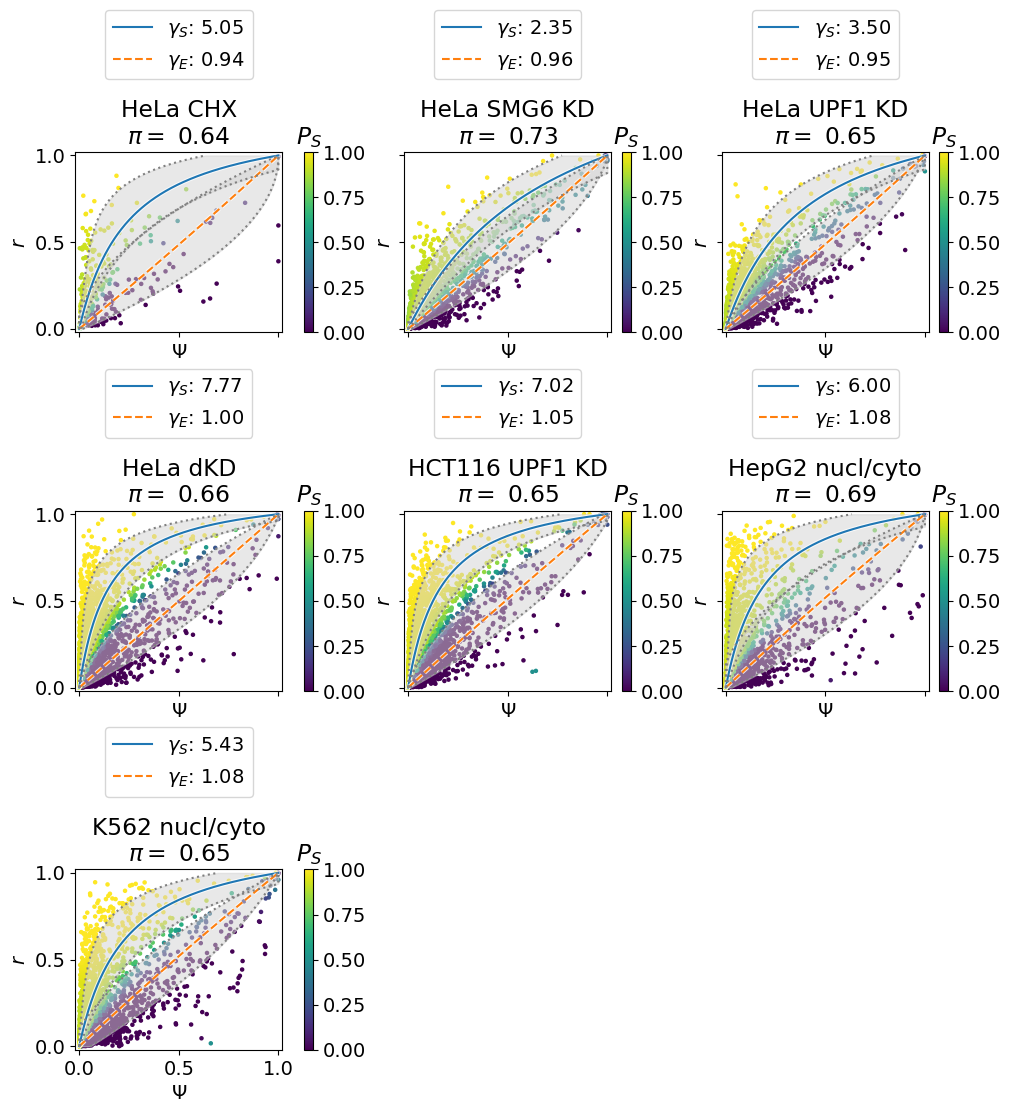

In [39]:
%%time
good_res = dict()

responder_df = []
n_init=20
f,ax = plt.subplots(3,3,figsize=(10,11),sharex=True,sharey=True,constrained_layout=True)
ax = ax.flatten()
for i,key in enumerate(good_data):
    ctrl = ase[ase.experiment==key]
    exper = use[use.experiment==key].copy()

    exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)]
    ctrl = ctrl[(ctrl.ctrl_psi!=0)&(ctrl.exp_psi!=0)]

    if (ctrl.shape[0]==0) or (exper.shape[0]==0):
        print(f'no data for {key}')
        continue
    try:
        lambda_sigma = 0
        success,params,prob,other,results = plot_dataset(exper,ctrl,n_init=n_init,ax=ax[i],lambda_sigma=lambda_sigma)
        exper['prob'] = prob
        responder_df.append(exper)
    except Exception as e:
        print(key)
        print(e)
        continue
    good_res[key] = params
    t = ax[i].get_title()
    ax[i].set_title(f'{key}\n{t}')
    ax[i].set_xlim(-0.02,1.02)
    ax[i].set_ylim(-0.02,1.02)
    xlab = ax[i].get_xlabel()
    ylab = ax[i].get_ylabel()
    #ax[i].set_xlabel(None)
    #ax[i].set_ylabel(None)
    ax[i].legend(loc='lower center', bbox_to_anchor=(0.5,1.35))
#f.supxlabel(xlab)
#f.supylabel(ylab)
for j in range(i+1,len(ax)):
    f.delaxes(ax[j])

responder_df = pd.concat(responder_df)
responder_df.to_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t',index=False)

In [40]:
f.savefig('./figures/Fig3_mm_supplementary.pdf',bbox_inches='tight')

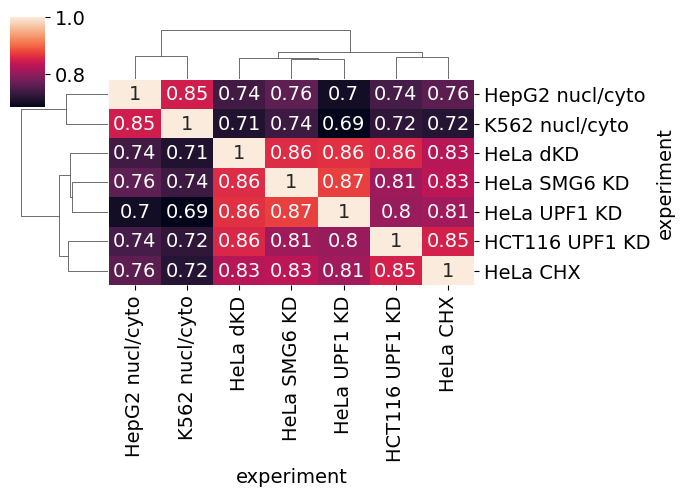

In [41]:
aa = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
responder_df = aa
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='responder')
#mat = mat[mat.notna().all(1)]

#aa = mat.isna().sum(1)
#bb = aa.value_counts()
#bb = bb.loc[sorted(bb.index)]
#ind = aa[aa<2].index
#mat - mat.loc[ind]

from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
mat = mat.corr(method=pairwise)

g = sns.clustermap(mat,annot=True,fmt='.2g',figsize=(7,5))

In [42]:
responder_df = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')

In [43]:
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

In [44]:
responder_df.groupby('experiment').responder.agg('mean')

experiment
HCT116 UPF1 KD     0.680149
HeLa CHX           0.717325
HeLa SMG6 KD       0.800112
HeLa UPF1 KD       0.705121
HeLa dKD           0.691289
HepG2 nucl/cyto    0.736734
K562 nucl/cyto     0.694392
Name: responder, dtype: float64

In [45]:
responder_df = responder_df[~responder_df.experiment.isin(['fractioning_A549','HeLa_SMG7_KD'])].copy()

In [46]:
responder_df.experiment = responder_df.experiment.str.replace('fractioning','frac')
res.experiment = res.experiment.str.replace('fractioning','frac')

In [47]:
responder_df.experiment.unique()

array(['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD',
       'HCT116 UPF1 KD', 'HepG2 nucl/cyto', 'K562 nucl/cyto'],
      dtype=object)

In [48]:
mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='responder')
#mat = mat[mat.notna().all(1)]

#aa = mat.isna().sum(1)
#bb = aa.value_counts()
#bb = bb.loc[sorted(bb.index)]
#ind = aa[aa<2].index
#mat - mat.loc[ind]

from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
mat = mat.corr(method=pairwise)

g = sns.clustermap(mat,annot=True,fmt='.2g',figsize=(6,5))
plt.close()

order = [i._text for i in g.ax_heatmap.get_xticklabels()]

f,ax = plt.subplots(1,3,figsize=(10,5),constrained_layout=True)


tmp = res[res.experiment.isin(order)].copy()
tmp.experiment = tmp.experiment.astype('category').cat.reorder_categories(order)
tmp = tmp.sort_values('experiment')
sns.boxplot(data=tmp,y='experiment',x='a1_hat',showfliers=False,ax=ax[0],color='lightgrey',linecolor='black')
ax[0].set_xlabel('$\gamma$')
ax[0].set_ylabel(None)

ax[0].axvline(1,ls=':',c='black')

t1 = ax[0].get_yticklabels()


corr = mat.loc[order,order].copy()
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
corr = corr.iloc[0:,:-1]
mask = mask[0:,:-1]
sns.heatmap(corr, mask=mask, annot=True, fmt='.2g', linewidths=.5, ax=ax[1],annot_kws={"size": 10})

ax[1].set_xticklabels(ax[1].get_xticklabels(),ha='right',rotation=45,rotation_mode='anchor')
#ax[1].set_xticklabels(ax[1].get_xticklabels(),ha='left',rotation=-45,rotation_mode='anchor')
ax[1].set_xlabel(None)
ax[1].set_ylabel(None)
ax[1].set_yticks([])

from matplotlib.ticker import MaxNLocator
ax[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

t2 = ax[1].get_yticklabels()
f.axes[-1].set_title('F1')
plt.close()

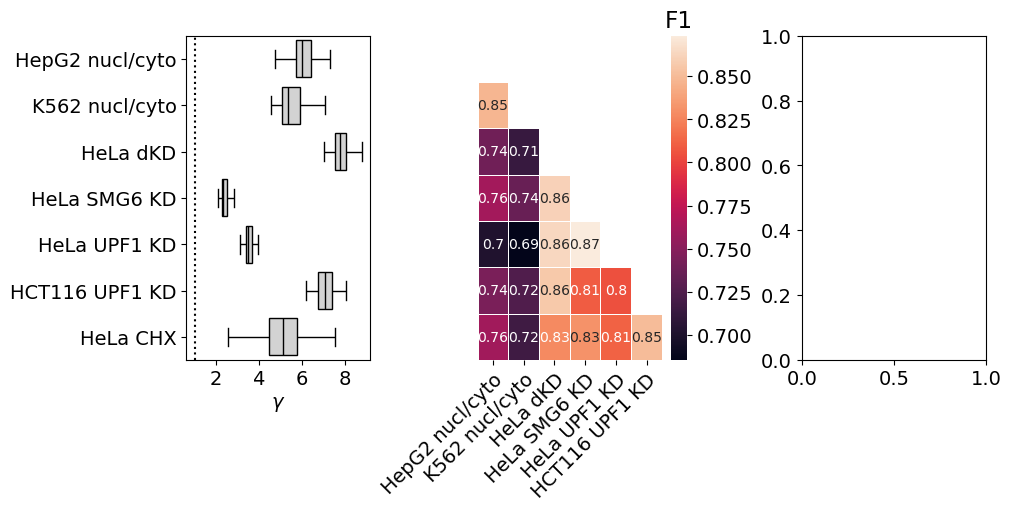

In [49]:
f

### LogFC of R vs NR

In [50]:
responders = responder_df

In [51]:
files = [
    './nmd_inactivation_data/deseq_res/deseq_res_CHX.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_chx.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_dKD.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_SMG6_KD.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_SMG7_KD.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_UPF1_KD.tsv',
        ]

lfc = []
for file in files:
    tmp = pd.read_csv(file,sep='\t',index_col=[0])
    name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
    tmp['experiment'] = name
    tmp['gene_id'] = tmp.index
    lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
    
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/HCT116_UPF1_KD_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)

#lfc.experiment = lfc.experiment.replace('hela_chx_24h','HeLa_chx')
#lfc.experiment = lfc.experiment.str.replace('fractioning','frac')

def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr
lfc.experiment = replace(lfc.experiment)

In [52]:
lfc.experiment.unique()

array(['CHX', 'HeLa CHX', 'HeLa dKD', 'HeLa SMG6 KD', 'HeLa SMG7 KD',
       'HeLa UPF1 KD', 'RIPiT', 'HepG2 nucl/cyto', 'K562 nucl/cyto',
       'HCT116 UPF1 KD'], dtype=object)

In [53]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [54]:
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [55]:
condition = (responders.prob>0.5)&(responders.exp_psi>0.05)
responders['responder'] = np.where(condition,'S','E')

In [56]:
aa = responders
resp = cat.merge(aa).sort_values('responder',ascending=False)[['gene_id','experiment','responder']].drop_duplicates()

In [57]:
resp.experiment.unique()

array(['K562 nucl/cyto', 'HCT116 UPF1 KD', 'HeLa UPF1 KD', 'HeLa SMG6 KD',
       'HepG2 nucl/cyto', 'HeLa dKD', 'HeLa CHX'], dtype=object)

In [58]:
resp = resp.merge(lfc)

In [59]:
resp[['experiment','responder']].value_counts(sort=False)

experiment       responder
HCT116 UPF1 KD   E            1537
                 S            1738
HeLa CHX         E             121
                 S             177
HeLa SMG6 KD     E            1604
                 S            1257
HeLa UPF1 KD     E            1620
                 S            1219
HeLa dKD         E            1533
                 S            1609
HepG2 nucl/cyto  E            1178
                 S            1117
K562 nucl/cyto   E            1335
                 S            1187
Name: count, dtype: int64

In [60]:
resp.experiment = resp.experiment.astype('category').cat.reorder_categories(order)
resp = resp.sort_values(['experiment','responder'],ascending=[True,False])

In [61]:
from importlib import reload
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\helper_functions.py'>

In [62]:
f.axes[2].clear()

In [63]:
sns.boxplot(data=resp,y='experiment',x='log2FoldChange',hue='responder',hue_order=['S','E'],showfliers=False,ax=ax[2])

ylabels = [t.get_text() for t in ax[0].get_yticklabels()]
ax[2].set_yticks([])
ax[2].set_ylabel(None)
ax[2].legend(title=None,loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)

ax[2].axvline(0,ls=':',c='black')


from statannotations.Annotator import Annotator

pairs = [((i,'S'),(i,'E')) for i in order]
annotator = Annotator(
    ax[2],
    pairs,
    data=resp,
    y='experiment',
    x='log2FoldChange',
    hue='responder',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()

hf.add_n(ylabels,ax[2],resp,y='experiment',x='log2FoldChange',orient='h',hue='responder',hue_order=['S','E'],pad=0.25,fontsize=10)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

K562 nucl/cyto_S vs. K562 nucl/cyto_E: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:8.916e-30 U_stat=1.002e+06
HepG2 nucl/cyto_S vs. HepG2 nucl/cyto_E: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:6.242e-31 U_stat=8.440e+05
HeLa dKD_S vs. HeLa dKD_E: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:6.590e-04 U_stat=1.333e+06
HeLa SMG6 KD_S vs. HeLa SMG6 KD_E: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.371e-05 U_stat=1.112e+06
HeLa UPF1 KD_S vs. HeLa UPF1 KD_E: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=1.006e+06
HCT116 UPF1 KD_S vs. HCT116 UPF1 KD_E: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.370e-19 U_stat=1.586e+06
HeLa

<Figure size 640x480 with 0 Axes>

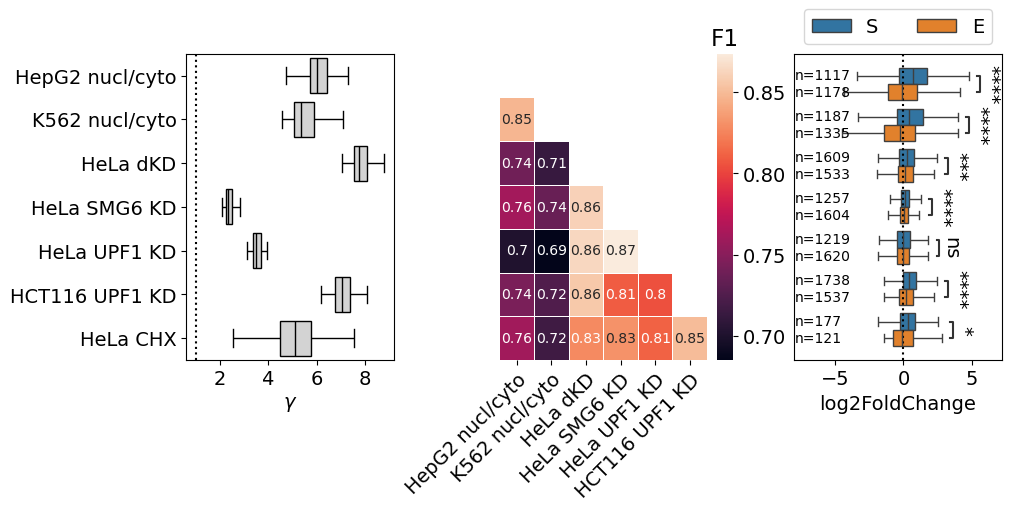

In [64]:
f

In [65]:
ax = f.axes[0]
pos = ax.get_position()
pos.x0 = 0.1
pos.x1 = 0.34
ax.set_position(pos)
f.axes[2].set_xlabel(r'$\log_2$FC')

Text(0.5, 116.61275235454902, '$\\log_2$FC')

In [66]:
pos.x1

np.float64(0.34)

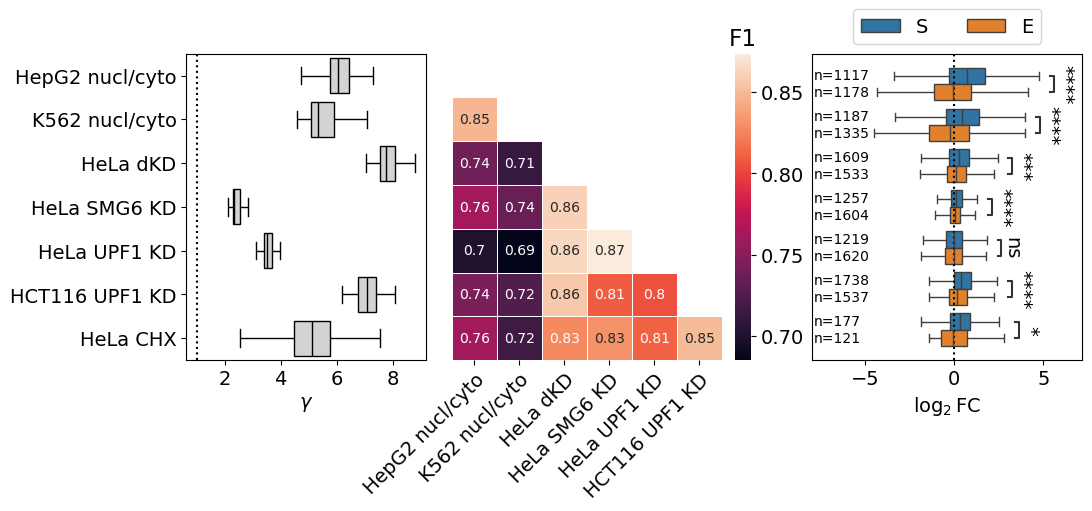

In [67]:
f

In [68]:
f.savefig('./figures/Fig3_mm_stability_consistency_and_logFC.pdf',bbox_inches='tight')

In [69]:
aa = responders[responders.experiment=='HeLa_dKD'][['src','event_id','responder']].drop_duplicates()
masha = aa.merge(catalog)
masha.to_csv('C:/Users/zavil/Downloads/responders.tsv',sep='\t',index=False)

### PhyloP and RiboSeq

In [70]:
phylop = pd.read_csv('C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_periodicity.539events.csv')
phylop = phylop[(phylop.cons == "phylop30_pos")&(phylop.region == "up")].copy()
phylop.responder = phylop.responder.map({True:'S',False:'E'})

In [71]:
tmp = phylop.copy()
f,(ax,ax2) = plt.subplots(1,2,figsize=(10,1.5),constrained_layout=True,sharey=True)
sns.boxplot(data=tmp,y='responder',x='dcons',hue='responder',showfliers=False,ax=ax)
ax.set_xlabel('Coding potential')
ax.set_ylabel(None)


from statannotations.Annotator import Annotator

pairs = [('S','E')]
annotator = Annotator(
    ax,
    pairs,
    data=tmp,
    y='responder',
    x='dcons',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
#    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()

ylabels = [t.get_text() for t in ax.get_yticklabels()]
hf.add_n(ylabels,ax,tmp,y='responder',x='dcons',orient='h',pad=0.2,fontsize=12)
plt.close()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

S vs. E: Mann-Whitney-Wilcoxon test two-sided, P_val:3.749e-02 U_stat=2.580e+04


In [72]:
#riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_w_ribosome_profiling_EMTAB.539events.csv'
riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE_up_down_regions_w_ribosome_profiling_EMTAB_cov_matched_subset.csv'

riboseq = pd.read_csv(riboseq,usecols=['src','event_id','responder','cov_whole','cov_up','cov_down',
                                       'width_whole','width_up','width_down','readth_fr','matching_group'])
riboseq.responder = riboseq.responder.map({True:'S',False:'E'})

#### Overlap with other isoforms

In [73]:
import pyranges as pr
def read_gtf(file):
    df = pr.read_gtf(file).df
    c1 = ['Chromosome', 'Source', 'Feature', 'Start', 'End', 'Score', 'Strand', 'Frame']
    c2 = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame']
    d = dict(zip(c1,c2))
    df = df.rename(columns=d)
    df.start+=1
    return df

In [74]:
%%time
gtf = read_gtf('./gtfs/ensembl_filtered.gtf')

CPU times: total: 1min
Wall time: 1min


In [75]:
riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE_up_down_regions_w_ribosome_profiling_EMTAB_cov_matched_subset.csv'
df = pd.read_csv(riboseq)
df = df[['src','event_id','stop_cod','ex']]
df[['chrn','start','end','strand']] = pd.DataFrame(df.ex.str.split('_').tolist())
df[['start','end']] = df[['start','end']].astype(int)
df['down_start'] = np.where(df.strand=='+', df.stop_cod, df.start)
df['down_end'] = np.where(df.strand=='+', df.end, df.stop_cod)

In [76]:
cds = gtf[gtf.type=='CDS']

In [77]:
cols = ['src', 'event_id', 'chrn', 'strand', 'down_start', 'down_end']
df = catalog[['src','event_id','gene_id']].drop_duplicates().merge(df[cols]).drop_duplicates()

In [78]:
df.shape,cds.shape

((287, 7), (741347, 26))

In [79]:
import duckdb
query = """
    SELECT COUNT(*)
    FROM df
    JOIN cds
        ON df.strand = cds.strand
        AND df.chrn = cds.chrn
        AND df.down_start <= cds.end
        AND df.down_end >= cds.start
"""

duckdb.query(query).fetchone()

(3,)

In [80]:
query = """
    SELECT
        df.src,
        df.event_id,
        cds.transcript_id
    FROM df
    JOIN cds
        ON df.strand = cds.strand
        AND df.chrn = cds.chrn
        AND df.down_start <= cds.end
        AND df.down_end >= cds.start
"""

mapping = duckdb.query(query).to_df()

In [81]:
mapping[['src','event_id']].drop_duplicates().merge(df)

,src,event_id,gene_id,chrn,strand,down_start,down_end
0,ensembl,ENSG00000197102_4,ENSG00000197102,chr14,+,102014032,102014247
1,ensembl,ENSG00000082258_1,ENSG00000082258,chr2,+,134945813,134945982


In [82]:
mapping.event_id.unique()

array(['ENSG00000197102_4', 'ENSG00000082258_1'], dtype=object)

#### Plot

In [83]:
#riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_w_ribosome_profiling_EMTAB.539events.csv'
riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE_up_down_regions_w_ribosome_profiling_EMTAB_cov_matched_subset.csv'

riboseq = pd.read_csv(riboseq,usecols=['src','event_id','responder','cov_whole','cov_up','cov_down',
                                       'width_whole','width_up','width_down','readth_fr','matching_group'])
riboseq.responder = riboseq.responder.map({True:'S',False:'E'})

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

S vs. E: Mann-Whitney-Wilcoxon test two-sided, P_val:1.046e-02 U_stat=4.040e+03


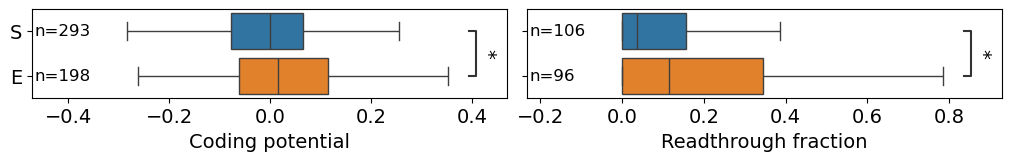

<Figure size 640x480 with 0 Axes>

In [84]:
tmp = riboseq[(riboseq.width_up>10)&(riboseq.width_down>5)&(riboseq.cov_up>0.1)]

sns.boxplot(data=tmp,y='responder',x='readth_fr',hue='responder',showfliers=False,ax=ax2)

pairs = [('S','E')]
annotator = Annotator(
    ax2,
    pairs,
    data=tmp,
    y='responder',
    x='readth_fr',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
#    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()


ax2.set_xlabel('Readthrough fraction')
ax2.set_ylabel(None)

ylabels = [t.get_text() for t in ax.get_yticklabels()]
hf.add_n(ylabels,ax2,tmp,y='responder',x='readth_fr',orient='h',pad=0.2,fontsize=12)

f

In [85]:
f.savefig('./figures/Fig3_phylop_and_riboseq.pdf',bbox_inches='tight')

## Figure 4

In [86]:
GAMMA = 'gamma_emp'

In [87]:
responders = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
condition = (responders.exp_psi>0.05)&(responders.prob>0.5)
responders['responder'] = np.where(condition,'S','E')

In [88]:
gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
gamma = gamma[(gamma.ctrl_psi!=0)&(gamma.exp_psi!=0)].copy()
gamma['gamma_emp'] = hf.psir2gamma(gamma.ctrl_psi,gamma.exp_psi)

<Axes: xlabel='gamma_emp', ylabel='Density'>

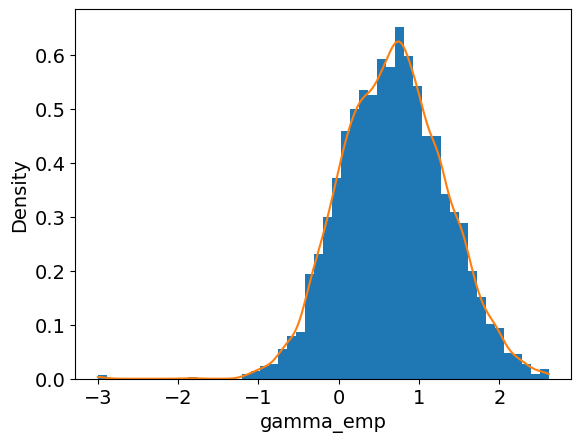

In [89]:
f,ax = plt.subplots()
aa = gamma[(gamma.experiment=='HeLa dKD')&(np.isfinite(gamma[GAMMA]))][GAMMA]
#aa = aa[aa<20]
aa = np.log10(aa+0.001)
plt.hist(aa,density=True,bins=50)
sns.kdeplot(aa,bw_adjust=0.8,cut=0,ax=ax)
#plt.axvline(0.38)
#plt.axvline(point,c='red')
#plt.axvline(0.8)

In [90]:
resp = gamma.merge(responders)

In [91]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HCT116 UPF1 KD', 'HeLa CHX',
       'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

In [92]:
resp = resp[(resp.ctrl_psi!=0)&(resp.exp_psi!=0)]

#### Psi ~ expr corcoef in GTEx

In [93]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [94]:
from scipy.stats import spearmanr

In [95]:
%%time
import pickle
with open('psi_expression_gtex.pkl', "rb") as f:
    psi = pickle.load(f)

CPU times: total: 4.97 s
Wall time: 5.17 s


In [96]:
catalog[['src','event_id']].drop_duplicates().src.value_counts()

src
ensembl    10831
chess       3731
Name: count, dtype: int64

In [97]:
psi['psi'] = psi.num/psi.denom

In [98]:
%%time

res = []
i=0

import time
start_time = time.time()
for key,tmp in psi[(psi.psi!=0)&(psi.expr.notna())].groupby(['src','event_id']):
    i+=1
    if i%10000==1:
        print(f'Done {i}',time.time()-start_time)
    if len(tmp)<40:
        continue
    if np.std(tmp.psi)==0:
        continue
    r,p = spearmanr(tmp.expr,tmp.psi,nan_policy='omit')
    res.append([*key,r,p])
res = pd.DataFrame(res,columns=['src','event_id','r','p'])
!mkdir gtex
res.to_csv('./gtex/cor_expr_vs_psi_gtex_all_tissues_nozero.csv')

<timed exec>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


Done 1 5.107392072677612


Done 10001 107.88497734069824


CPU times: total: 15min
Wall time: 1min 57s


A subdirectory or file gtex already exists.


In [99]:
res = []

In [100]:
psi['dthr'] = (psi.denom>15).astype(int)
psi['psi'] = psi.num/psi.denom
meanpsi = psi.groupby(['src','event_id'],observed=True).agg({'psi':['mean','std'],'dthr':'mean'})
meanpsi.columns = ['psi','psi_std','dthr']
meanpsi = meanpsi.reset_index()

meanpsi['cv'] = meanpsi.psi_std/meanpsi.psi

In [101]:
coefs = pd.read_csv('./gtex/cor_expr_vs_psi_gtex_all_tissues_nozero.csv',index_col=[0])

In [102]:
df = coefs.merge(resp).merge(meanpsi)

In [103]:
pthr = 1 
stdthr = 0
cvthr = 1 
psithr = 0.01 
dthr = 0.6

formula = 'r ~ psi_z + responder'
formula2 = 'r ~ psi_z + gamma_i_z'
tmp = df[(df.experiment=='HeLa dKD')&(df.p<pthr)&(df.psi_std>stdthr)&(df.cv>cvthr)&(df.psi>psithr)&(df.dthr>dthr)].copy()
tmp['gamma_i_z'] = np.log(tmp[GAMMA])
tmp.gamma_i_z = (tmp.gamma_i_z-np.mean(tmp.gamma_i_z))/np.std(tmp.gamma_i_z)
tmp['psi_z'] = (tmp.psi-np.mean(tmp.psi))/np.std(tmp.psi)
print(tmp.shape)
hf.get_ols_res(formula,tmp)

(1500, 19)


,coef,std_err,t,p_value,ci_lower,ci_upper,adj_R,F_pval
Intercept,-0.346680,0.008681,-39.934459,4.921846e-238,-0.363708,-0.329651,0.047791,4.436386e-17
responder[T.S],-0.032733,0.011075,-2.955458,3.170874e-03,-0.054458,-0.011008,0.047791,4.436386e-17
psi_z,0.045132,0.005390,8.373169,1.272034e-16,0.034559,0.055705,0.047791,4.436386e-17


In [104]:
hf.get_ols_res(formula2,tmp)

,coef,std_err,t,p_value,ci_lower,ci_upper,adj_R,F_pval
Intercept,-0.366800,0.005381,-68.162705,0.000000e+00,-0.377355,-0.356244,0.049802,9.115135e-18
psi_z,0.043112,0.005398,7.986393,2.746447e-15,0.032523,0.053700,0.049802,9.115135e-18
gamma_i_z,-0.018638,0.005398,-3.452759,5.703425e-04,-0.029227,-0.008050,0.049802,9.115135e-18


In [105]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['src','event_id','gene_id','event_type']].drop_duplicates().copy()

In [106]:
tmp = tmp.merge(cat)

In [107]:
tmp['psi_bin'] = pd.qcut(tmp.psi,5)
tmp['coef_sign'] = (tmp.r>0).map({True:1,False:-1})

In [108]:
tmp[GAMMA].describe()

count    1500.000000
mean       15.196952
std        31.652542
min         0.013609
25%         2.094442
50%         5.585726
75%        15.053732
max       356.818182
Name: gamma_emp, dtype: float64

In [109]:
def p2star(p):
    thrs = [0.0001,0.001,0.01,0.05,0.1]
    star = ['****','***','**','*','·']
    for t,s in zip(thrs,star):
        if p<t:
            return s
    return ""

def add_N(col,sep='\n',brac=True):
    d = col.value_counts()
    if brac:
        d = {k:f'{k}{sep}$(n={v})$'  for k,v in d.items()}
    else:
        d = {k:f'{k}{sep}$n={v}$'  for k,v in d.items()}
    return col.map(d)

In [110]:
tmp.responder.value_counts()

responder
S    922
E    578
Name: count, dtype: int64

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

S
$n=922$ vs. E
$n=578$: Mann-Whitney-Wilcoxon test two-sided, P_val:1.092e-02 U_stat=2.457e+05


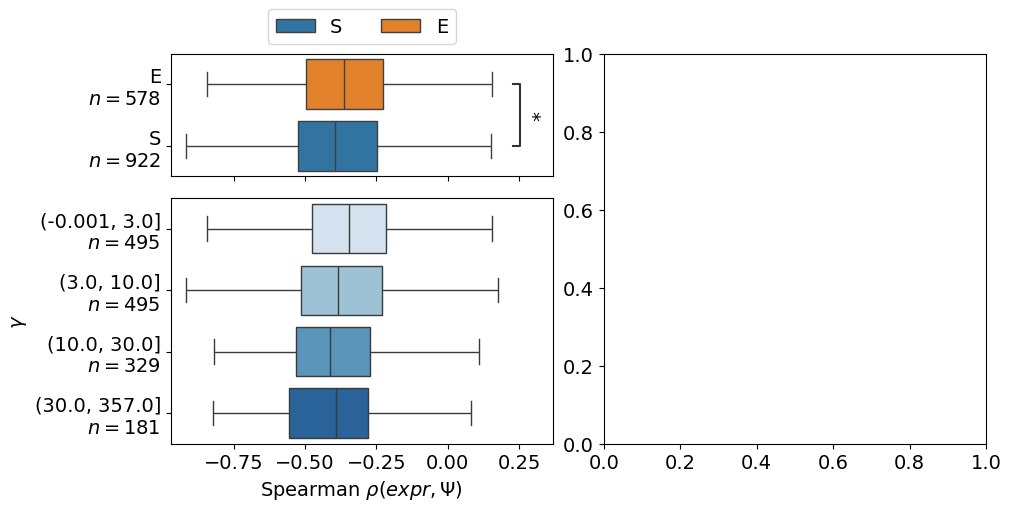

In [111]:
tmp2 = tmp.copy()

bins = [0,3,10,30,int(max(tmp2[GAMMA]))+1]

if GAMMA == 'gamma_i':
    tmp2['gamma_bin'] = pd.cut(
        tmp2[GAMMA],
        bins
    )
else:
    tmp2['gamma_bin'] = pd.cut(
        tmp2[GAMMA],
        bins,
        include_lowest=True
    )

tmp2.responder = add_N(tmp2.responder, sep='\n', brac=False)
tmp2.gamma_bin = add_N(tmp2.gamma_bin, sep='\n', brac=False)
tmp2 = tmp2.sort_values('responder', ascending=False)


def jitter(ax, width):
    for l in ax.lines:
        if l.get_marker() != '':
            xs = l.get_xdata()
            xs += np.random.uniform(-width, width, len(xs))
            l.set_xdata(xs)


flierprops = {'marker': '.', 'ms': 3}
showfliers = False


f, axes = plt.subplot_mosaic(
    """
    AC
    BC
    """,
    layout="constrained",
    figsize=(10,5),
    width_ratios=(1,1),
    height_ratios=(1, 2),
)

ax1, ax2 = axes['A'], axes['B']

ax2.sharex(ax1)
ax1.tick_params(labelbottom=False)

# ------------------------
# responder comparison
# ------------------------
sns.boxplot(
    data=tmp2,
    x='r',
    y='responder',
    ax=ax1,
    hue='responder',
    legend=True,
    flierprops=flierprops,
    showfliers=showfliers,
    orient='h'
)

# ------------------------
# gamma bins
# ------------------------
sns.boxplot(
    data=tmp2,
    x='r',
    y='gamma_bin',
    hue='gamma_bin',
    palette='Blues',
    flierprops=flierprops,
    showfliers=showfliers,
    ax=ax2,
    legend=False,
    orient='h'
)
h,l = ax1.get_legend_handles_labels()

ax1.legend(handles=h,labels=[i.split('\n')[0] for i in l],ncol=2,loc='lower center',bbox_to_anchor=(0.5,1))

for ax in [ax1,ax2]:
    ax.set_xlabel(None)
    jitter(ax, 0.05)

ax2.set_xlabel(r'Spearman $\rho(expr,\Psi)$')

# ========================
# Statistical annotation
# ========================

from statannotations.Annotator import Annotator

pairs = [tuple(tmp2.responder.unique())]

annotator = Annotator(
    ax1,
    pairs,
    data=tmp2,
    y="responder",
    x="r",
    orient='h'
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside"
)

annotator.apply_and_annotate()

ax1.set_ylabel(None)
ax2.set_ylabel(r'$\gamma$')

# если нужен прежний порядок категорий
ax1.invert_yaxis()

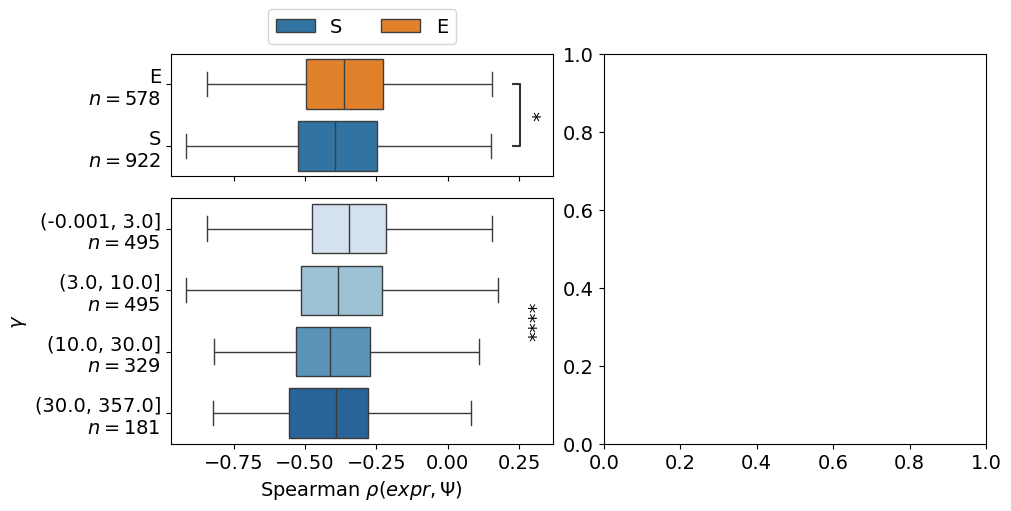

In [112]:
formula = 'r ~ gamma_i_z'
df = hf.get_ols_res(formula, tmp2)

p = df.loc['gamma_i_z', 'p_value']
star = p2star(p)

star_text = ax1.texts[0]

x, y = star_text.get_position()
x_disp, y_disp = star_text.get_transform().transform((x, y))
x2, y2 = ax2.transData.inverted().transform((x_disp, y_disp))

import matplotlib.transforms as transforms

trans2 = transforms.blended_transform_factory(ax2.transData,ax2.transAxes)

ax2.text(x2,0.5,star,ha='left',va='center',rotation=90,transform=trans2)
f

#### logFC vs gamma in NMDKD

In [113]:
lfc = []
for file in glob.glob('./nmd_inactivation_data/deseq_res/*tsv'):
    if not (("ripit" in file.lower()) or ("fractioning" in file.lower())):
        tmp = pd.read_csv(file,sep='\t',index_col=[0])
        name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
        tmp['experiment'] = name
        tmp['gene_id'] = tmp.index
        lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)

#lfc.experiment = lfc.experiment.replace('hela_chx_24h','HeLa_chx')
#lfc.experiment = lfc.experiment.str.replace('fractioning','frac')
lfc.experiment = replace(lfc.experiment)

In [114]:
files = [
    './nmd_inactivation_data/deseq_res/deseq_res_CHX.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_chx.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_dKD.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_SMG6_KD.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_SMG7_KD.tsv',
    './nmd_inactivation_data/deseq_res/HeLa_UPF1_KD.tsv',
        ]

lfc = []
for file in files:
    tmp = pd.read_csv(file,sep='\t',index_col=[0])
    name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
    tmp['experiment'] = name
    tmp['gene_id'] = tmp.index
    lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
    
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/HCT116_UPF1_KD_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)
lfc.experiment = replace(lfc.experiment)

In [115]:
df = resp.merge(cat).merge(lfc).sort_values(GAMMA,ascending=False).drop_duplicates(['experiment','gene_id'])

In [116]:
lfc.experiment.unique()

array(['CHX', 'HeLa CHX', 'HeLa dKD', 'HeLa SMG6 KD', 'HeLa SMG7 KD',
       'HeLa UPF1 KD', 'RIPiT', 'HepG2 nucl/cyto', 'K562 nucl/cyto',
       'HCT116 UPF1 KD'], dtype=object)

In [117]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HCT116 UPF1 KD', 'HeLa CHX',
       'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

In [118]:
fill = max(df.loc[df[GAMMA]!=np.inf,GAMMA])
df[GAMMA] = np.where(df[GAMMA]==np.inf,fill,df[GAMMA])

In [119]:
bins = [0,3,10,30,int(max(df[GAMMA]))+1]
df['gamma_bin'] = pd.cut(df[GAMMA],bins)

In [120]:
axes['C'].clear()

In [121]:
aa = df[(df.exp_psi>0.01)&(df.ctrl_psi>0.01)].groupby('experiment').gamma_bin.value_counts().reset_index()
aa.pivot(index='experiment',columns='gamma_bin').fillna(0).astype(int)

count                           
gamma_bin       (0, 3] (3, 10] (10, 30] (30, 813]
experiment                                       
HCT116 UPF1 KD     804     715      409        87
HeLa CHX           126      75       37        13
HeLa SMG6 KD      1185     466       41         7
HeLa UPF1 KD      1007     577       86         6
HeLa dKD           701     626      332       114
HepG2 nucl/cyto    588     405      199       125
K562 nucl/cyto     784     478      230        71

In [122]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HCT116 UPF1 KD', 'HeLa CHX',
       'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD'], dtype=object)

In [123]:
order = ['HepG2 nucl/cyto','K562 nucl/cyto','HeLa dKD','HeLa SMG6 KD','HeLa UPF1 KD','HCT116 UPF1 KD','HeLa CHX',]

combs = list(combinations(df.gamma_bin.unique(),2))
pairs = [((i,l1),(i,l2)) for l1,l2 in combs for i in order]

In [124]:
df[df.gamma_bin.isna()]

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,gamma_emp,prob,responder,gene_id,event_type,log2FoldChange,gamma_bin
10892,chess,ENSG00000158286_1,HeLa SMG6 KD,1.0,0.977528,34.000000,44.500000,hela_kd,0.0,2.914319e-01,E,ENSG00000158286,IR,0.272852,NaN
18326,chess,ENSG00000204681_0,HeLa dKD,1.0,0.994536,19.000000,91.500000,hela_kd,0.0,6.676033e-02,E,ENSG00000204681,EE,1.444695,NaN
7295,ensembl,ENSG00000008988_0,HCT116 UPF1 KD,1.0,0.999679,2612.500000,4149.000000,HCT116_UPF1_KD,0.0,1.209221e-01,E,ENSG00000008988,IR,-0.618716,NaN
14384,chess,ENSG00000158286_1,HeLa UPF1 KD,1.0,0.908815,34.000000,54.833333,hela_kd,0.0,5.071338e-01,S,ENSG00000158286,IR,0.661411,NaN
10083,ensembl,ENSG00000101901_1,HeLa CHX,1.0,0.596296,16.500000,54.500000,hela_chx,0.0,7.807785e-06,E,ENSG00000101901,A5SS,1.073256,NaN
14451,chess,ENSG00000164975_5,HeLa UPF1 KD,1.0,0.996114,135.166667,257.333333,hela_kd,0.0,5.512162e-02,E,ENSG00000164975,PE|PE2|alt_start,0.886804,NaN
18011,chess,ENSG00000158286_1,HeLa dKD,1.0,0.872727,34.000000,36.666667,hela_kd,0.0,7.546691e-02,E,ENSG00000158286,IR,-0.546789,NaN
10145,ensembl,ENSG00000132478_0,HeLa CHX,1.0,0.389749,20.250000,58.250000,hela_chx,0.0,4.170786e-13,E,ENSG00000132478,alt_end,1.498514,NaN
9919,ensembl,ENSG00000265817_0,HCT116 UPF1 KD,1.0,0.983402,47.500000,80.333333,HCT116_UPF1_KD,0.0,1.941630e-01,E,ENSG00000265817,alt_end,-2.078595,NaN


In [125]:
df

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,gamma_emp,prob,responder,gene_id,event_type,log2FoldChange,gamma_bin
21144,ensembl,ENSG00000248643_0,HeLa dKD,0.995110,1.000000,136.333333,497.333333,hela_kd,812.978142,7.745107e-02,E,ENSG00000248643,alt_end|complex,0.286156,"(30.0, 813.0]"
2504,ensembl,ENSG00000008988_0,K562 nucl/cyto,0.999248,1.000000,1187.200000,515.500000,fractioning,812.978142,8.085306e-03,E,ENSG00000008988,IR,-3.058937,"(30.0, 813.0]"
19547,ensembl,ENSG00000117569_1,HeLa dKD,0.274336,1.000000,18.833333,124.333333,hela_kd,812.978142,1.000000e+00,S,ENSG00000117569,EE,1.812670,"(30.0, 813.0]"
13740,ensembl,ENSG00000248643_0,HeLa SMG6 KD,0.995110,1.000000,136.333333,105.833333,hela_kd,812.978142,9.182010e-02,E,ENSG00000248643,alt_end|complex,-0.046415,"(30.0, 813.0]"
13752,ensembl,ENSG00000260007_0,HeLa SMG6 KD,0.955679,1.000000,30.083333,47.166667,hela_kd,812.978142,1.000000e+00,S,ENSG00000260007,PE,0.653062,"(30.0, 813.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10083,ensembl,ENSG00000101901_1,HeLa CHX,1.000000,0.596296,16.500000,54.500000,hela_chx,0.000000,7.807785e-06,E,ENSG00000101901,A5SS,1.073256,NaN
14451,chess,ENSG00000164975_5,HeLa UPF1 KD,1.000000,0.996114,135.166667,257.333333,hela_kd,0.000000,5.512162e-02,E,ENSG00000164975,PE|PE2|alt_start,0.886804,NaN
18011,chess,ENSG00000158286_1,HeLa dKD,1.000000,0.872727,34.000000,36.666667,hela_kd,0.000000,7.546691e-02,E,ENSG00000158286,IR,-0.546789,NaN
10145,ensembl,ENSG00000132478_0,HeLa CHX,1.000000,0.389749,20.250000,58.250000,hela_chx,0.000000,4.170786e-13,E,ENSG00000132478,alt_end,1.498514,NaN


In [126]:
axes['C'].clear()

In [127]:
import matplotlib.transforms as transforms
if GAMMA == 'gamma_i':
    df['gamma_bin'] = pd.cut(df[GAMMA],bins)
    #df['gamma_bin'] = pd.qcut(df[GAMMA],4)
else:
    df['gamma_bin'] = pd.cut(df[GAMMA],bins)

df = df[(df.exp_psi>0.01)&(df.ctrl_psi>0.01)&(df.exp_psi<0.99)&(df.ctrl_psi<0.99)].copy()
tmp = df.copy()
filt = tmp.groupby(['experiment','gamma_bin'],sort=False,observed=True).size()
filt = filt[filt>20].reset_index().merge(tmp)

filt.experiment = filt.experiment.astype('category').cat.reorder_categories(order)
filt.sort_values('experiment')

#f,ax = plt.subplots()
ax = axes['C']
sns.boxplot(data=filt,y='experiment',x='log2FoldChange',hue='gamma_bin',showfliers=False,ax=ax,palette='Blues')

ylabels = [t.get_text() for t in ax.get_yticklabels()]
hue_order = filt.gamma_bin.sort_values().unique()
hf.add_n(ylabels,ax,filt,y='experiment',x='log2FoldChange',orient='h',hue='gamma_bin',hue_order=hue_order,pad=0.15,fontsize=8)

#sns.violinplot(data=filt,y='experiment',x='log2FoldChange',hue='gamma_bin',ax=ax,palette='Blues')
ax.legend(title=r'$\gamma$',loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)
#ax.legend(title=r'$\gamma$')
ax.set_ylabel(None)

ax.axvline(0,ls=':',c='black')

formula = 'r ~ gamma_i_z'
for l in ax.get_yticklabels():
    formula = 'log2FoldChange ~ gamma_i_z'
    key,pos = l._text,l._y
    tmp = df[df.experiment==key].copy()
    tmp['gamma_i_z'] = np.log10(tmp[GAMMA])
    tmp.gamma_i_z = (tmp.gamma_i_z-np.mean(tmp.gamma_i_z))/np.std(tmp.gamma_i_z)
    aa = hf.get_ols_res(formula, tmp)
    p = aa.loc['gamma_i_z', 'p_value']
    star = p2star(p)
    trans = transforms.blended_transform_factory(ax.transAxes,ax.transData)
    ax.text(1.01,pos,star,ha='left',va='center',transform=trans,rotation=90)


C:\Users\zavil\tcga_paper\NMDeq\nmd_psi\helper_functions.py:188: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = counts.groupby([cat, hue]).size()


In [128]:
f.axes[1].set_xlabel(r'$\log_2$FC')

Text(0.5, 0, '$\\log_2$FC')

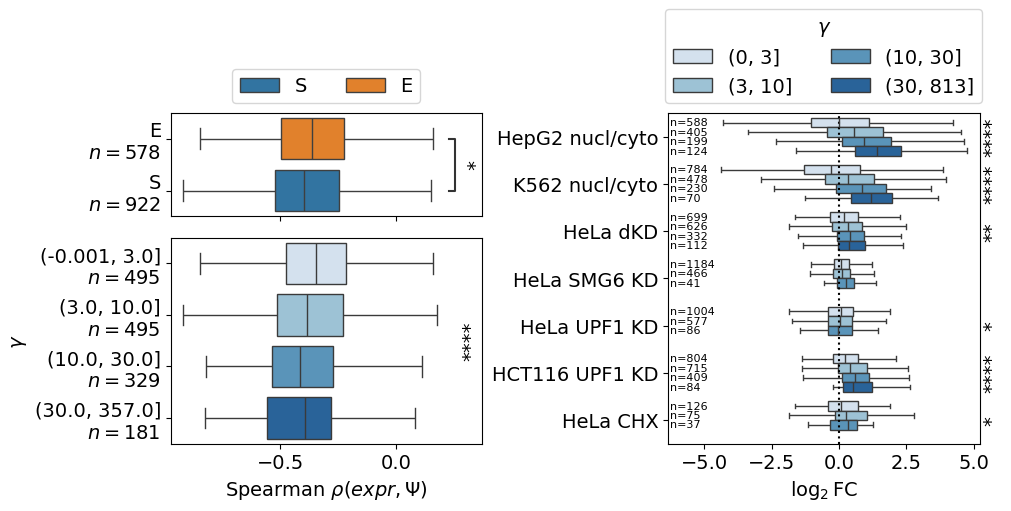

In [129]:
f

In [130]:
f.savefig('./figures/Fig4_gtex_and_logFC_in_NMDKD.pdf',bbox_inches='tight')

## Figure 5 (Individual figures examples)

In [131]:
d = {'RIC8B':'ENSG00000111785_2','PSPC1':'ENSG00000121390_0',
     'NFAT5':'ENSG00000102908_0','U2SURP':'ENSG00000163714_0',
     'RAB5IF':'ENSG00000101084_0','NCSTN':'ENSG00000162736_3'}

df = pd.DataFrame({'gene_name':d.keys(),'event_id':d.values(),'src':'ensembl'})

cols = ['gene_id','src','event_id','nmd_id_list','coding_id_list']
aa = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'][cols+['long_id']]
aa = aa.merge(df)
aa['long_id'] = aa.long_id.apply(lambda x: set() if 'chr_' in x else set([int(i) for i in x.split('_')[1:-1]]))
aa = aa.groupby(cols,as_index=False).long_id.agg(lambda x: set.union(*x))
aa['vmin'] = aa.long_id.map(min)
aa['vmax'] = aa.long_id.map(max)

df = aa.drop('long_id',axis=1).merge(df)

In [132]:
qpcr = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE.csv')
qpcr[qpcr.TARGET.isin(df.gene_name)].TARGET.unique()
qpcr = qpcr[(qpcr.TARGET.isin(df.gene_name))&(qpcr.EXPERIMENT=='UT')&(qpcr.EXP_TYPE=='KD')].copy()

qpcr = qpcr.sort_values(['TARGET','Replicate'])
qpcr['rep'] = [i//2 for i in range(qpcr.shape[0])]

bad_rep = [17,37,38]
qpcr = qpcr[~qpcr.rep.isin(bad_rep)].sort_values(['TARGET','rep','CHX'])

In [133]:
stat = qpcr.pivot(index=['TARGET','rep'],columns='CHX',values='PSI').reset_index()

In [134]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

In [135]:
pvals = stat.groupby('TARGET').apply(lambda x: ttest_rel(x[True],x[False])[1])
padj = multipletests(pvals,method='bonferroni')[1]
padj = pd.Series(padj,index=pvals.index,name='padj')

C:\Users\zavil\AppData\Local\Temp\ipykernel_22372\3042233526.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pvals = stat.groupby('TARGET').apply(lambda x: ttest_rel(x[True],x[False])[1])


In [136]:
def qpcr_boxplot(row,ax):
    tmp = qpcr[qpcr.TARGET==row.gene_name].copy()
    tmp.CHX = np.where(tmp.CHX,'$+$CHX','$-$CHX')
    sns.boxplot(data=tmp,x='CHX',y='PSI',fill=False,color='darkgrey',ax=ax,legend=False,showfliers=False)
    sns.stripplot(data=tmp,x="CHX",y="PSI",color='black',legend=False,ax=ax,s=3)
    
    pairs = [('$-$CHX', '$+$CHX')]
    
    annotator = Annotator(
        ax,
        pairs,
        data=tmp,
        x='CHX',
        y='PSI'
    )
    
    annotator.set_pvalues([padj.loc[row.gene_name] ])
    
    annotator.configure(
        text_format="star",     
        loc="inside"
    )
    
    annotator.annotate()

    ax.set_ylabel('$\Psi$')
    ax.set_xlabel(None)

In [137]:
import plotgtf as pg
from importlib import reload
reload(pg)

<module 'plotgtf' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\plotgtf.py'>

In [138]:
def crop_gtf(x,vmin,vmax):
    cond = (x.start<=vmax)&(x.end>=vmin)
    gtf = x[cond].copy()
    gtf.loc[gtf.start<vmin,'start'] = vmin
    gtf.loc[gtf.end>vmax,'end'] = vmax
    return gtf

In [139]:
def get_coverage(file,chrn,start,end):
    exe = '~/soft/ucsc/bigWigToBedGraph'
    cmd = f'wsl sh -c "{exe} -range={chrn}:{start}-{end} {file} stdout"'
    return pg.read_shell(cmd,header=None,names=['chrn','start','end','coverage'])

In [140]:
def plot(x,figsize=(4,2),
         riboseq_file='../project/bigwig/HCT_N_AID_UPF1_12h_IAA_2.uniq.bw',
         trs=None,all_transcripts=False,
         width_ratios=(1,4),height_ratios=(1,1,1),
         shrink=True,rel_length=0.5):
    row = x.copy()

    gene = gtf[gtf.gene_name==row.gene_name]

    if all_transcripts:
        nmd = list(gene[gene.transcript_biotype=='nonsense_mediated_decay'].transcript_id.unique())
        coding = list(gene[gene.transcript_biotype=='protein_coding'].transcript_id.unique())
    else:
        nmd = row.nmd_id_list.split(', ')
        coding = row.coding_id_list.split(', ')
    if trs:
        nmd = list(set(nmd)&set(trs))
        coding = list(set(coding)&set(trs))
    
    gene = gene[gene.transcript_id.isin(nmd+coding)]
    row.vmin = max(row.vmin,gene.start.min())
    row.vmax = min(row.vmax,gene.end.max())
    
    cmap = plt.get_cmap('tab10')
    highlight = dict()
    for t in coding:
        highlight[t] = cmap(0)
    for t in nmd:
        highlight[t] = 'red'
    
    gene = crop_gtf(gene,row.vmin-200,row.vmax+200).sort_values('transcript_biotype',ascending=False)
    
    f, ax = plt.subplot_mosaic(
        """
        DA
        DB
        DC
        """,
        figsize=figsize,
        width_ratios=width_ratios,
        height_ratios=height_ratios,
    )
    ax1,ax2,ax3,ax4 = ax['A'],ax['B'],ax['C'],ax['D']
    plt.subplots_adjust(wspace=0.1,hspace=0)
    ax2.sharex(ax1)
    ax3.sharex(ax1)
    ax1,mapper = pg.plot_gene(
        gene,
        collapse=True,
        shrink=shrink,
        intron_size='rel',
        rel_length=rel_length,
        highlight=highlight,
        ax=ax1,
        arrows=False,
        arrow_kwargs={'n':10,'s':15,'fixed_strand':True},
        max_tr=1
    )
    ax1.set_ylim(-0.5, len(ax1.get_yticks()) - 0.5)
    ax1.margins(0)
    
    ax1.set_title(row.gene_name)
    ax1.get_xaxis().set_visible(False)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_visible(False)
    for ax in [ax2,ax3]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    cov = get_coverage(riboseq_file,gene.chrn.iloc[0],row.vmin-100,row.vmax+100)
    pg.draw_coverage(ax2,cov,mapper=mapper)
    ax2.set_ylabel('Ribo-Seq',ha='right',va='center',rotation=0)

    cov = get_coverage('../project/bigwig/hg38.phastCons30way.bw',gene.chrn.iloc[0],row.vmin-100,row.vmax+100)
    cov.coverage = np.maximum(cov.coverage,0)
    pg.draw_coverage(ax3,cov,mapper=mapper,color='LimeGreen')
    ax3.set_ylabel('phastCons',ha='right',va='center',rotation=0)

    for ax in [ax1,ax2]:
        if mapper is not None:
            ax.set_xlim(mapper.transform(row.vmin-100),mapper.transform(row.vmax+100))
        else:
            ax.set_xlim(row.vmin-100,row.vmax+100)
        ax.set_xticks([])
        ax.margins(y=0)
    if gene.strand.iloc[0]=='-':
        for ax in [ax1,ax2,ax3]:
            ax.invert_xaxis()
    qpcr_boxplot(row,ax4)
    return f,[ax1,ax2,ax3,ax4]
    

In [141]:
!mkdir "./figures/examples"

A subdirectory or file ./figures/examples already exists.


In [142]:
df2 = df[df.gene_name=='NFAT5'].copy()
df2.vmax+=500

In [143]:
df.loc[df.gene_name=='RIC8B','vmin'] = 106870900

In [144]:
trs = {'RAB5IF':['ENST00000344795','ENST00000483815'],
       'NFAT5':['ENST00000349945', 'ENST00000354436', 'ENST00000567239','ENST00000426654','ENST00000393742'],
       'PSPC1':['ENST00000619300','ENST00000492741'],
       'NCSTN':['ENST00000699553','ENST00000459963'],
       'RIC8B':['ENST00000392837','ENST00000462949'],
       'U2SURP':['ENST00000488497','ENST00000473835','ENST00000493598']}

In [145]:
tab = gtf[gtf.type=='transcript'][['transcript_id','transcript_biotype','tag']]
trtab = []
for k,v in trs.items():
    for el in v:
        trtab.append([k,el])
tab = pd.DataFrame(trtab,columns=['gene_name','transcript_id']).merge(tab)

tab['mane'] = tab.tag.fillna('').str.contains('MANE_Select')

order = ['RAB5IF','RIC8B','U2SURP','PSPC1','NCSTN','NFAT5']

tab.gene_name = tab.gene_name.astype('category').cat.reorder_categories(order)
tab = tab.sort_values(['gene_name','transcript_biotype','mane']).drop_duplicates(['gene_name','transcript_biotype'],keep='last')
tab = tab[['gene_name','transcript_id','transcript_biotype']]
tab = tab.pivot(index='gene_name',columns='transcript_biotype',values='transcript_id').reset_index()

In [146]:
tmp = catalog[(catalog.src=='ensembl')&(catalog.event_id.isin(d.values()))][['event_id','long_id']]
tmp[['chrn','start','end','strand']] = pd.DataFrame(tmp.long_id.str.split('_').tolist(),index=tmp.index)
tmp[['start','end']] = tmp[['start','end']].astype(int)
tmp = tmp.groupby(['event_id','chrn']).agg({'start':'min','end':'max'}).reset_index()

tmp['gene_name'] = tmp.event_id.map(pd.Series(d.keys(),index=d.values()))

In [147]:
from urllib.parse import quote

def make_ucsc_link(row):
    chrom = row["chrn"]
    start = int(row["start"])
    end = int(row["end"])

    position = f"{chrom}:{max(1, start - 100)}-{end + 100}"
    highlight = f"{chrom}:{start}-{end}"

    url = (
        "https://genome.ucsc.edu/cgi-bin/hgTracks"
        f"?db=hg38"
        f"&position={quote(position, safe=':-')}"
        f"&highlight={quote('hg38.' + highlight, safe='.-:')}"
    )

    return rf"\href{{{url}}}{{{chrom}:{start}-{end}}}"

tmp["coordinates"] = tmp.apply(make_ucsc_link, axis=1)

In [148]:
tab = tab.merge(tmp[['gene_name','coordinates']]).rename(columns={'gene_name':'Gene name',
                                                            'nonsense_mediated_decay':'NMD transcript ID',
                                                            'protein_coding':'Coding transcript ID',
                                                            'coordinates':'Coordinates'})

In [149]:
tab.to_latex('./tables/ST_fig5.tex',index=False)

In [150]:
plt.rcParams.update({'font.size': 12})

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.642e-03


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.000e+00


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


...

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:4.143e-02


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.945e-01


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.519e-02
CPU times: total: 4.92 s
Wall time: 8.46 s


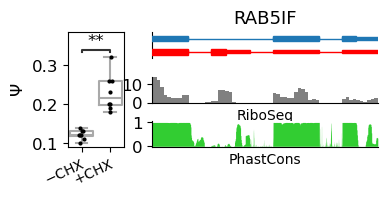

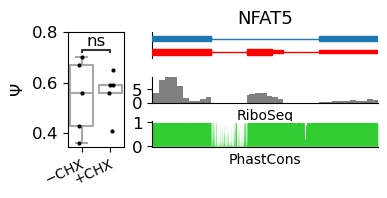

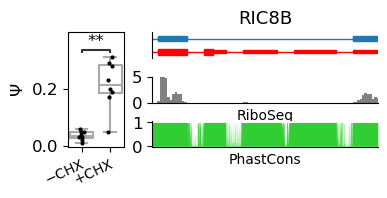

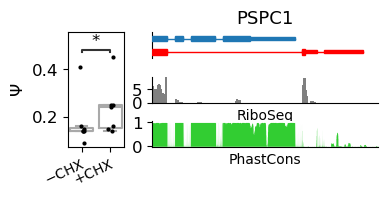

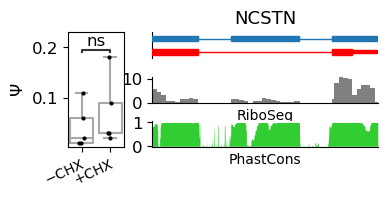

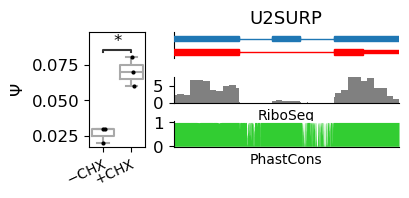

In [151]:
%%time
reload(pg)
for _,row in df.iterrows():
    trlist = None if row.gene_name not in trs.keys() else trs[row.gene_name]
    f,ax = plot(row,trs=trlist,figsize=(4,1.5))
    plt.subplots_adjust(wspace=0.2,hspace=0.7)
    ax[0].set_yticks([])
    ax[0].set_title(ax[0].get_title(),fontsize=13)
    ax[1].set_ylabel(None)
    ax[2].set_ylabel(None)
    
    ax[1].set_xlabel('RiboSeq',fontsize=10)
    ax[2].set_xlabel('PhastCons',fontsize=10)
    axs = ax[3]
    axs.set_xticklabels(axs.get_xticklabels(),rotation=25,ha='right',rotation_mode='anchor',fontsize=10)
    f.savefig(f'./figures/examples/{row.gene_name}.pdf',bbox_inches='tight',transparent=True)

A subdirectory or file ./figures/ctrl_examples already exists.


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.642e-03


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.000e+00


...

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:4.143e-02


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.945e-01


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.519e-02
CPU times: total: 4.64 s
Wall time: 6.38 s


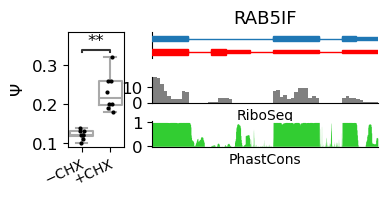

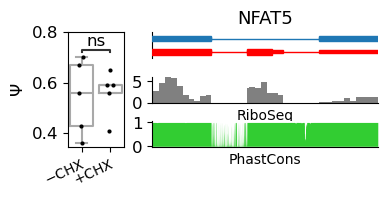

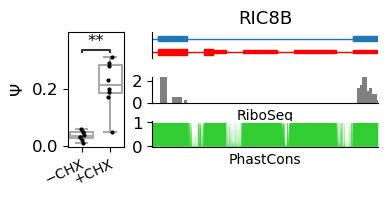

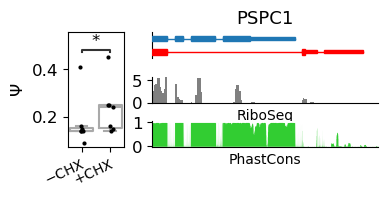

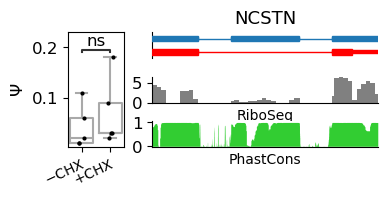

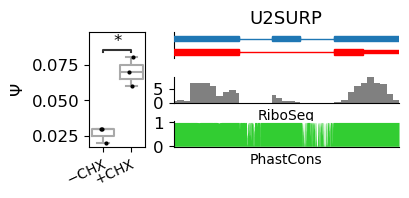

In [152]:
%%time
!mkdir "./figures/ctrl_examples"
reload(pg)
for _,row in df.iterrows():
    trlist = None if row.gene_name not in trs.keys() else trs[row.gene_name]
    f,ax = plot(row,trs=trlist,figsize=(4,1.5), riboseq_file='../project/bigwig/HCT_N_AID_UPF1_0h_IAA_2.uniq.bw')
    plt.subplots_adjust(wspace=0.2,hspace=0.7)
    ax[0].set_yticks([])
    ax[0].set_title(ax[0].get_title(),fontsize=13)
    ax[1].set_ylabel(None)
    ax[2].set_ylabel(None)
    
    ax[1].set_xlabel('RiboSeq',fontsize=10)
    ax[2].set_xlabel('PhastCons',fontsize=10)
    axs = ax[3]
    axs.set_xticklabels(axs.get_xticklabels(),rotation=25,ha='right',rotation_mode='anchor',fontsize=10)
    f.savefig(f'./figures/ctrl_examples/{row.gene_name}.pdf',bbox_inches='tight',transparent=True)

In [153]:
plt.rcParams.update({'font.size': 14})

### Merge example figures

In [154]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pypdf import PdfReader, PdfWriter

output = "./figures/examples/legend.pdf"

cmap = plt.get_cmap('tab10')
handles = [
    Patch(facecolor=cmap(0), label='Coding'),
    Patch(facecolor='red', label='NMD'),
]

fig = plt.figure()
legend = fig.legend(
    handles=handles,
    ncol=2,
    frameon=False,
    loc="center",
    borderaxespad=0,
)

# Обновляем размеры и положение легенды
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
bbox = legend.get_window_extent(renderer=renderer)

# Переводим размеры из пикселей в дюймы
dpi = fig.dpi
width = bbox.width / dpi
height = bbox.height / dpi

# Создаём фигуру точно под легенду
fig.set_size_inches(width, height)
legend.set_bbox_to_anchor((0.5, 0.5), transform=fig.transFigure)

fig.savefig(
    output,
    format="pdf",
    bbox_inches=None,
    pad_inches=0,
)

plt.close(fig)

# Принудительно обрезаем страницу по размерам легенды
reader = PdfReader(output)
page = reader.pages[0]

page.cropbox.lower_left = (0, 0)
page.cropbox.upper_right = (
    float(page.mediabox.width),
    float(page.mediabox.height),
)

writer = PdfWriter()
writer.add_page(page)

with open(output, "wb") as f:
    writer.write(f)

In [155]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pypdf import PdfReader, PdfWriter, Transformation
from pypdf._page import PageObject

files = [
    "./figures/examples/RAB5IF.pdf",
    "./figures/examples/RIC8B.pdf",
    "./figures/examples/U2SURP.pdf",
    "./figures/examples/PSPC1.pdf",
    "./figures/examples/NCSTN.pdf",
    "./figures/examples/NFAT5.pdf",
]

output_file = "./figures/examples/combined.pdf"
legend_file = "./figures/examples/legend.pdf"



# --- 2. Загружаем рисунки и легенду ---
pages = [PdfReader(f).pages[0] for f in files]
legend_page = PdfReader(legend_file).pages[0]

w = max(float(p.mediabox.width) for p in pages)
h = max(float(p.mediabox.height) for p in pages)

lw = float(legend_page.mediabox.width)
lh = float(legend_page.mediabox.height)

# --- 3. Рассчитываем размеры панели ---
overlap_h = 0
overlap_v = 0.15

dx = w - overlap_h * w
dy = h - overlap_v * h

panel_width = w + dx
panel_height = h + 2 * dy

# Расстояние между легендой и панелью, в points
legend_gap = 0

canvas_height = panel_height + legend_gap + lh

canvas = PageObject.create_blank_page(
    width=panel_width,
    height=canvas_height,
)

# --- 4. Размещаем шесть рисунков ---
positions = [
    (0,  2 * dy),
    (dx, 2 * dy),
    (0,  dy),
    (dx, dy),
    (0,  0),
    (dx, 0),
]

for page, (x, y) in zip(pages, positions):
    canvas.merge_transformed_page(
        page,
        Transformation().translate(x, y),
    )

# --- 5. Добавляем легенду сверху по центру ---
legend_x = (panel_width - lw) / 2
legend_y = panel_height + legend_gap

canvas.merge_transformed_page(
    legend_page,
    Transformation().translate(legend_x, legend_y),
)

# --- 6. Сохраняем итоговый PDF ---
writer = PdfWriter()
writer.add_page(canvas)

with open(output_file, "wb") as f:
    writer.write(f)


In [156]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pypdf import PdfReader, PdfWriter, Transformation
from pypdf._page import PageObject

files = [
    "./figures/ctrl_examples/RAB5IF.pdf",
    "./figures/ctrl_examples/RIC8B.pdf",
    "./figures/ctrl_examples/U2SURP.pdf",
    "./figures/ctrl_examples/PSPC1.pdf",
    "./figures/ctrl_examples/NCSTN.pdf",
    "./figures/ctrl_examples/NFAT5.pdf",
]

output_file = "./figures/ctrl_examples/combined.pdf"
legend_file = "./figures/examples/legend.pdf"



# --- 2. Загружаем рисунки и легенду ---
pages = [PdfReader(f).pages[0] for f in files]
legend_page = PdfReader(legend_file).pages[0]

w = max(float(p.mediabox.width) for p in pages)
h = max(float(p.mediabox.height) for p in pages)

lw = float(legend_page.mediabox.width)
lh = float(legend_page.mediabox.height)

# --- 3. Рассчитываем размеры панели ---
overlap_h = 0
overlap_v = 0.15

dx = w - overlap_h * w
dy = h - overlap_v * h

panel_width = w + dx
panel_height = h + 2 * dy

# Расстояние между легендой и панелью, в points
legend_gap = 0

canvas_height = panel_height + legend_gap + lh

canvas = PageObject.create_blank_page(
    width=panel_width,
    height=canvas_height,
)

# --- 4. Размещаем шесть рисунков ---
positions = [
    (0,  2 * dy),
    (dx, 2 * dy),
    (0,  dy),
    (dx, dy),
    (0,  0),
    (dx, 0),
]

for page, (x, y) in zip(pages, positions):
    canvas.merge_transformed_page(
        page,
        Transformation().translate(x, y),
    )

# --- 5. Добавляем легенду сверху по центру ---
legend_x = (panel_width - lw) / 2
legend_y = panel_height + legend_gap

canvas.merge_transformed_page(
    legend_page,
    Transformation().translate(legend_x, legend_y),
)

# --- 6. Сохраняем итоговый PDF ---
writer = PdfWriter()
writer.add_page(canvas)

with open(output_file, "wb") as f:
    writer.write(f)


## Figure 6 (discussion)

(0.0, 1.0)

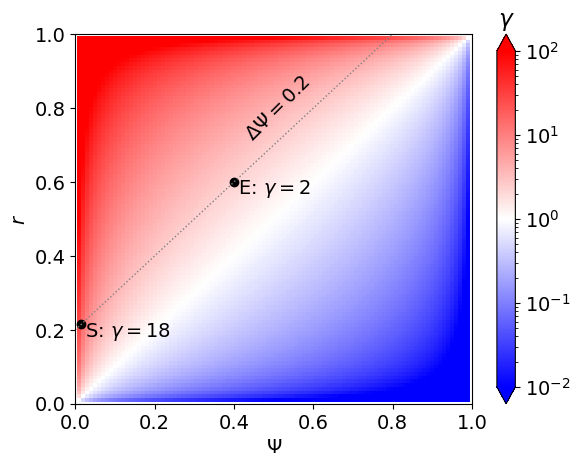

In [157]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors

psi = np.linspace(0, 1, 100)
r = np.linspace(0, 1, 100)

psi = psi[1:-1]
r = r[1:-1]

PSI, R = np.meshgrid(psi, r)

gamma = hf.psir2gamma(PSI,R)

f, ax = plt.subplots()

pcm = ax.pcolormesh(
    PSI, R, gamma,
    shading='auto',
    norm=colors.LogNorm(vmax=100,vmin=0.01),
#    norm=colors.LogNorm(),
    cmap='bwr'
)

cbar = plt.colorbar(pcm, ax=ax,extend='both')
cbar.ax.set_title('$\gamma$')


ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')

l = [0.2]
for dpsi in l:
    ax.plot([0,1],[dpsi,1+dpsi],lw=1,ls=':',c='grey')

x = 0.6
y = x+np.mean(l)
ax.text(x,y,rf'$\Delta\Psi={np.mean(l)}$',rotation=45,va='center',ha='right')

x1 = (1-np.mean(l))/2
x2 = 0.015
x = np.array([x1,x2])
y = x+np.mean(l)
ax.scatter(x,y,c='black')
g = hf.psir2gamma(x,y)
labels = [f'E: $\\gamma={g[0]:.0f}$',f'S: $\\gamma={g[1]:.0f}$']

offset=0.01
for xi,yi,t in zip(x,y,labels):
    ax.text(xi+offset,yi+offset,t,ha='left',va='top')

#ax.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2)
ax.set_xlim(0,1)
ax.set_ylim(0,1)

In [158]:
f.savefig('./figures/Fig6.pdf',bbox_inches='tight')

## Supplementary 

The order of supplementary figures here may not be the same as an actual order in the manuscript due to later rearrangements upon revision

### SF0 (Pipeline scheme)

In [159]:
tex_source = r'''
\documentclass[tikz,border=8pt]{standalone}

\usepackage{amsmath}
\usepackage{tikz}
\usetikzlibrary{arrows.meta, positioning, calc}

\begin{document}

\begin{tikzpicture}[
    block/.style={
        draw,
        rounded corners,
        minimum height=10mm,
        minimum width=28mm,
        align=center
    },
    arrow/.style={
        -{Latex[length=2.5mm]},
        thick
    },
    label/.style={
        font=\small,
        inner sep=2pt
    }
]

% =========================================================
% Upper level
% =========================================================

\node[block] (bam) {BAM};

\node[block, right=6mm of bam] (split)
    {split read counts};

\node[block, right=12mm of split] (psi)
    {$(\Psi_i, r_i)$};

\node[block, right=10mm of psi] (gammai)
    {$\gamma_i$};


% =========================================================
% Lower level
% =========================================================

\node[block, below=6mm of bam] (gtf)
    {GTF};

\node[block, right=6mm of gtf] (catalog)
    {catalog of AS events};

% Center gamma_S, gamma_E directly below gamma_i
\node[block, below=6mm of gammai] (gammaSE)
    {$\gamma_S,\ \gamma_E$};


% =========================================================
% Main upper branch
% =========================================================

\draw[arrow]
    (bam) -- (split);

\draw[arrow]
    (split) -- (psi);

% Psi -> gamma_i, Eq. 1
\draw[arrow]
    (psi) -- node[label, above] {Eq.~1} (gammai);


% =========================================================
% GTF branch
% =========================================================

\draw[arrow]
    (gtf) -- (catalog);


% =========================================================
% catalog of AS events -> middle of NMDj processing
%
% First horizontally right, then vertically upward.
% =========================================================

\coordinate (nmdmid)
    at ($(split)!0.55!(psi)$);

\coordinate (catalogturn)
    at (nmdmid |- catalog.east);

\draw[arrow]
    (catalog.east) -- (catalogturn) -- (nmdmid);


% =========================================================
% Psi -> gamma_S, gamma_E
%
% First vertically downward, then horizontally right.
% "mixture" is above the horizontal segment,
% "model" is below it.
% =========================================================

\coordinate (mixturn)
    at (psi.south |- gammaSE.west);

\draw[arrow]
    (psi.south) -- (mixturn)
    -- node[
        font=\small,
        inner sep=1pt,
        above,
        pos=0.5
    ] {mixture}
    node[
        font=\small,
        inner sep=1pt,
        below,
        pos=0.5
    ] {model}
    (gammaSE.west);


\end{tikzpicture}

\end{document}

'''

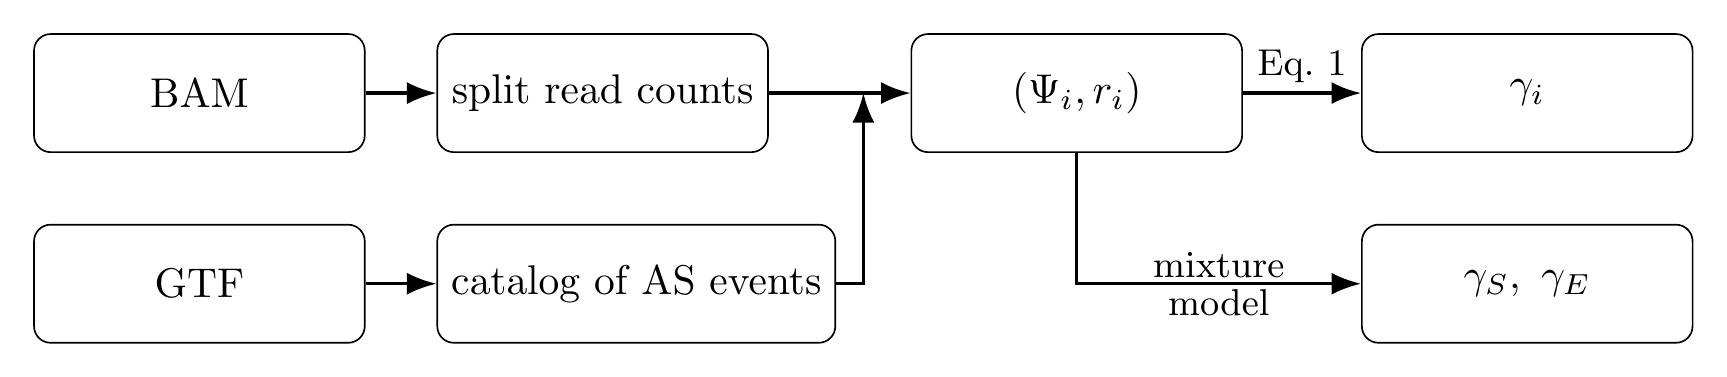

In [160]:
import subprocess
from pathlib import Path
from IPython.display import display, IFrame


tex_path = Path('./figures/pipeline.tex')

tex_path.write_text(tex_source, encoding="utf-8")

result = subprocess.run(
    [
        "pdflatex",
        "-interaction=nonstopmode",
        "-halt-on-error",
        tex_path.name
    ],
    cwd=tex_path.parent,
    capture_output=True,
    text=True
)

if result.returncode==0:

    from pdf2image import convert_from_path
    from IPython.display import display
    
    pages = convert_from_path("./figures/pipeline.pdf", dpi=300)
    
    display(pages[0])
else:
    print(result.stderr)

### SF 0.5 (mixture model for AS events 1 vs many in gene)

In [161]:
use = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
ase = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t')

use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)]
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)]

In [162]:
cat = catalog[['src','event_id','gene_id']].drop_duplicates()
aa = cat.gene_id.value_counts()
cat['n_events'] = cat.gene_id.map(aa)
cat['group'] = np.where(cat.n_events==1,'one event','multiple events')

prob 0.6890595009596929


prob 0.6934812760055479
CPU times: total: 2.33 s
Wall time: 2.33 s


Text(0.02, 0.5, '$r$')

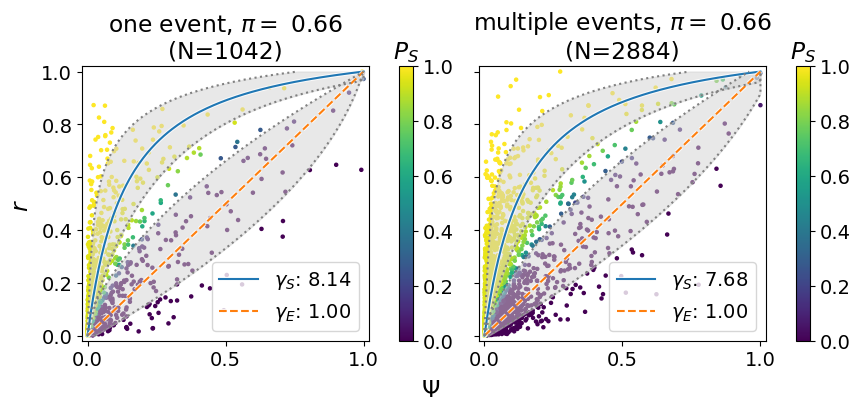

In [163]:
%%time
key = 'HeLa dKD'

names = ['one event','multiple events']
inits = [1,1,]

f,axes = plt.subplots(1,2,figsize=(8.5,4),constrained_layout=True,sharey=True)

for name,n_init,ax in zip(names,inits,axes):

    exper = cat[cat.group==name].reset_index().merge(use)
    exper = exper[exper.experiment==key].copy()
    N = exper[['src','event_id']].drop_duplicates().shape[0]
    ctrl = ase[ase.experiment==key].copy()

    plot_borders = True
    plot_dataset(exper,ctrl,n_init=n_init,ax=ax,plot_borders=plot_borders)
    t = ax.get_title()
    t+=f'\n(N={N})'
    ax.set_title(t)
    ax.set_title(f'{name}, {t}')
    ax.set_xlim(-0.02,1.02)
    ax.set_ylim(-0.02,1.02)
    
    xlab = ax.get_xlabel()
    ylab = ax.get_ylabel()
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    #ax.axis('equal')
f.supxlabel(xlab)
f.supylabel(ylab)

In [164]:
f.savefig('./figures/SF_one_event_vs_many.pdf',bbox_inches='tight')

### SF1 (psi-r for coding AS events)

In [165]:
import mm
from scipy.optimize import minimize

In [166]:
bindpsi = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',
                      sep='\t')
ctrl = bindpsi[bindpsi.experiment=='HeLa dKD'].copy()

In [167]:
N=1000
frac = 0.5
baseline = []
for _ in range(N):
    smpl = ctrl.sample(frac=frac)
    x_control = smpl.exp_psi.to_numpy()
    y_control = smpl.ctrl_psi.to_numpy()

    a0_hat = minimize(
        mm.residuals_control,
        x0=[2],
        args = (x_control,y_control),
        bounds=[(0.01, 500)]
    ).x[0]
    baseline.append(a0_hat)

In [168]:
x_control = ctrl.exp_psi.to_numpy()
y_control = ctrl.ctrl_psi.to_numpy()

In [169]:
l,h = np.quantile(baseline,2.5/100),np.quantile(baseline,1-2.5/100)

In [170]:
x = np.linspace(0,1,100)
low,high = mm.hyperbolic_curve(x, l),mm.hyperbolic_curve(x, h)

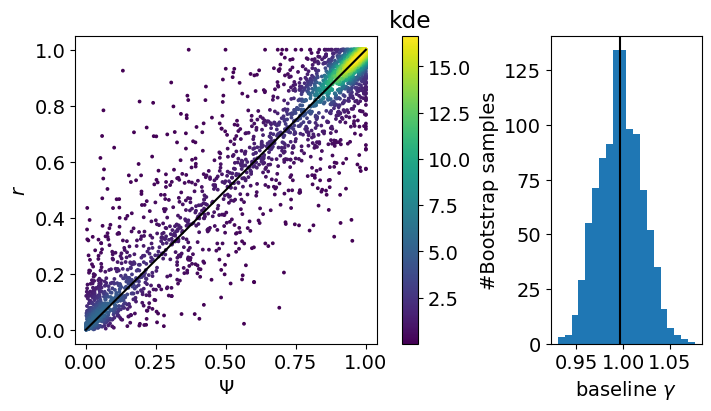

In [171]:
f,(ax,ax2) = plt.subplots(1,2,figsize=(7,4),width_ratios=(2,1),constrained_layout=True)
z,idx = hf.plot2d(y_control,x_control)
im = ax.scatter(y_control[idx],x_control[idx],c=z[idx],s=3)
cbar = plt.colorbar(im)
cbar.ax.set_title('kde')
ax2.hist(baseline,bins=20)
ax.axis('equal')
ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')
ax2.set_ylabel('#Bootstrap samples')
ax2.set_xlabel(r'baseline $\gamma$')

med = np.median(baseline)
ax2.axvline(med,c='black')

y = np.linspace(0,1,100)
x = mm.hyperbolic_curve(y,med)
ax.plot(x,y,c='black')

In [172]:
f.savefig('./figures/SF1.pdf',bbox_inches='tight')

### SF2 (Mixture model plots for all datasets)

[Jump here](#sf3)

### SF3 (NMD efficiency as in Colombo et al)

In [173]:
mask = 'C:/Users/zavil/arkuda_backup/expression/transcripts/hela_nmdkd/*/quant.sf'
files = list(glob.glob(mask))
tpm = []
for file in files:
    sample = os.path.basename(os.path.dirname(file))
    tmp = pd.read_csv(file,sep='\t')
    tmp['sample_id'] = sample
    tpm.append(tmp)
tpm = pd.concat(tpm)

In [174]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_full.tsv',sep='\t')

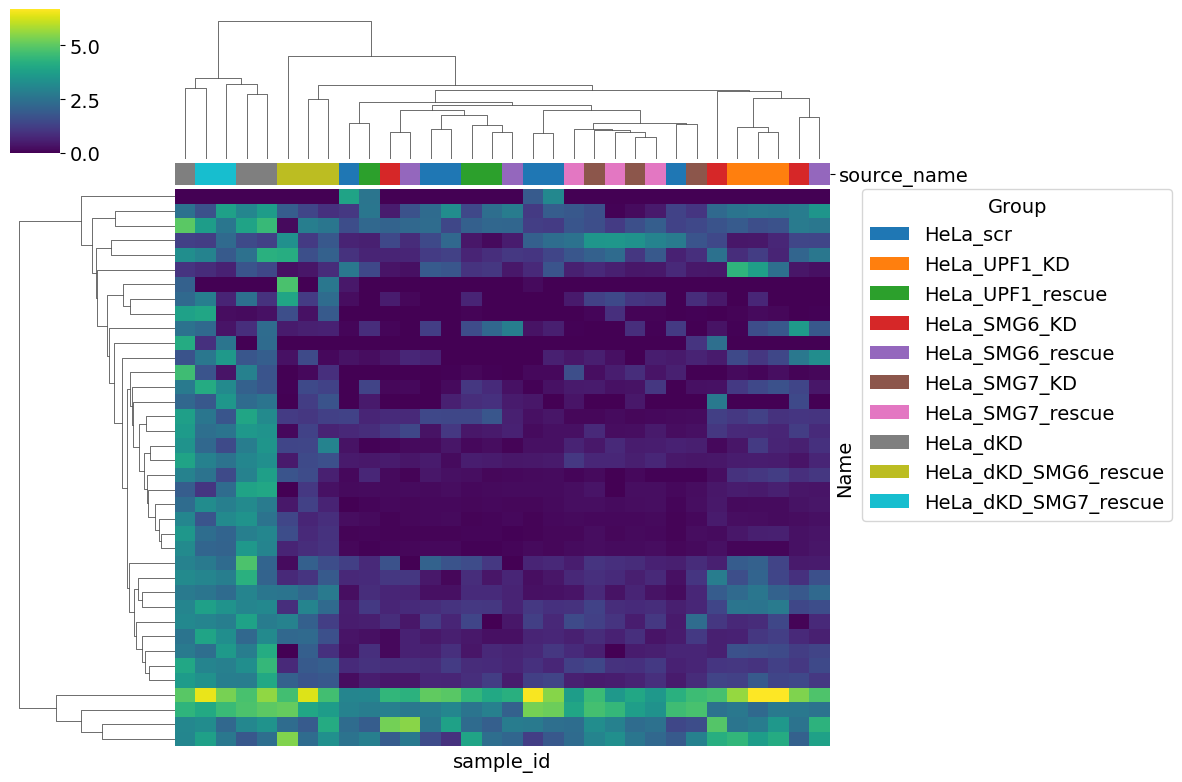

[]

In [175]:
from matplotlib.patches import Patch

aa = sets[(sets.set1==1)&(sets.src=='ensembl')][['src','event_id']].merge(catalog[['src','event_id',
                                                                                   'nmd_id_list']].drop_duplicates())
trs = set.union(*aa.nmd_id_list.str.split(', ').apply(set))
df = tpm[tpm.Name.isin(trs)]
df = df.pivot(index='Name',columns='sample_id',values='TPM').fillna(0)
mat = df.div(df.std(axis=1),axis=0)
mask = mat.isna().all(axis=1)
df = df[~mask]
mat = mat[~mask]

groups = meta.set_index('sample_id').source_name
groups = groups.reindex(mat.columns)

categories = groups.unique()
palette = dict(zip(
    categories,
    sns.color_palette("tab10", n_colors=len(categories))
))

# Series цветов с тем же индексом, что и колонки
col_colors = groups.map(palette)

g = sns.clustermap(
    mat,
    col_colors=col_colors,
    cmap="viridis",
    figsize=(10, 8),
    xticklabels=False,
    yticklabels=False
)

# Легенда
handles = [
    Patch(facecolor=palette[category], label=category)
    for category in categories
]

g.ax_heatmap.legend(
    handles=handles,
    title="Group",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    borderaxespad=0,
)

plt.show()
g.figure.axes[-2].set_xticks([])
g.figure.axes[-2].set_yticks([])

In [176]:
tpm = meta[['sample_id','source_name']].merge(tpm)
tpm['passed'] = ((tpm.TPM>2)&(tpm.NumReads>30)).astype(int)
filt = tpm.groupby(['Name','source_name']).passed.agg('min').reset_index()
filt.groupby('source_name').passed.agg('mean').sort_values()
filt[filt.passed==1].Name.nunique()/filt.Name.nunique()

0.4301392785078006

In [177]:
nmdtrs = catalog[catalog.src=='ensembl'][['nmd_id_list']].drop_duplicates()
nmdtrs = set.union(*nmdtrs.nmd_id_list.str.split(', ').apply(set))

In [178]:
filt[(filt.Name.isin(nmdtrs))&(filt.passed==1)].Name.nunique()/filt[(filt.Name.isin(nmdtrs))].Name.nunique()

0.42338927991337305

In [179]:
good_trs = filt[(filt.passed==1)].Name.unique()

In [180]:
meta.source_name.unique()

array(['HeLa_scr', 'HeLa_UPF1_KD', 'HeLa_UPF1_rescue', 'HeLa_SMG6_KD',
       'HeLa_SMG6_rescue', 'HeLa_SMG7_KD', 'HeLa_SMG7_rescue', 'HeLa_dKD',
       'HeLa_dKD_SMG6_rescue', 'HeLa_dKD_SMG7_rescue'], dtype=object)

In [181]:
src = meta.source_name.str.replace('HeLa_','')
meta['exp_type'] = src.apply(lambda x: x.split('_')[-1]).replace('scr','ctrl')
meta['gene'] = src.apply(lambda x: x.split('_')[0]).replace('scr','ctrl')

In [182]:
meta.source_name.unique()

array(['HeLa_scr', 'HeLa_UPF1_KD', 'HeLa_UPF1_rescue', 'HeLa_SMG6_KD',
       'HeLa_SMG6_rescue', 'HeLa_SMG7_KD', 'HeLa_SMG7_rescue', 'HeLa_dKD',
       'HeLa_dKD_SMG6_rescue', 'HeLa_dKD_SMG7_rescue'], dtype=object)

In [183]:
pairs = [('HeLa_scr', 'HeLa_UPF1_KD'), ('HeLa_UPF1_rescue', 'HeLa_UPF1_KD'),
         ('HeLa_scr', 'HeLa_SMG6_KD'), ('HeLa_SMG6_rescue', 'HeLa_SMG6_KD'),
         ('HeLa_scr', 'HeLa_SMG7_KD'), ('HeLa_SMG7_rescue', 'HeLa_SMG7_KD'),
         ('HeLa_scr', 'HeLa_dKD'), ('HeLa_dKD_SMG6_rescue', 'HeLa_dKD'), ('HeLa_dKD_SMG7_rescue', 'HeLa_dKD'),
        ]

In [184]:
tpmagg = tpm[tpm.Name.isin(good_trs)].groupby(['Name','source_name']).TPM.agg('mean').reset_index()

In [185]:
lfc = []
for ctrl, kd in pairs:
    tmp = tpmagg[tpmagg.source_name.isin([ctrl,kd])].pivot(index='Name',
                                                           columns='source_name',
                                                           values='TPM').rename(columns={ctrl:'ctrl_TPM',kd:'kd_TPM'})
    tmp['ctrl'] = ctrl
    tmp['kd'] = kd
    tmp['lfc_type'] = 'rescue' if 'rescue' in ctrl else 'kd'
    if ctrl=='HeLa_dKD_SMG6_rescue':
        tmp['kd']+='_smg6'
    if ctrl=='HeLa_dKD_SMG7_rescue':
        tmp['kd']+='_smg7'
    if (ctrl=='HeLa_scr') and (kd=='HeLa_dKD'):
        tmp2 = tmp.copy()
        tmp['kd']+='_smg6'
        tmp2['kd']+='_smg7'
        lfc.append(tmp2)
    lfc.append(tmp)
lfc = pd.concat(lfc).reset_index()

In [186]:
lfc['logFC'] = np.log2((lfc.kd_TPM+1)/(lfc.ctrl_TPM+1))

In [187]:
lfc = lfc.pivot(index=['Name','kd'],columns='lfc_type',values='logFC')
lfc['logFC'] = (lfc.kd+lfc.rescue)/2
lfc = lfc[['logFC']].reset_index().set_index('Name')

<Axes: xlabel='logFC', ylabel='nmdt'>

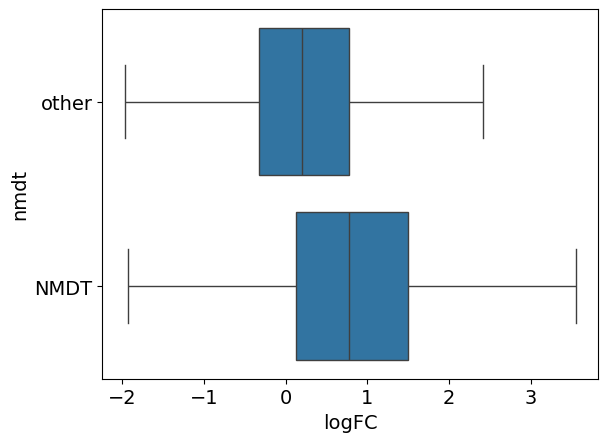

In [188]:
lfc['nmdt'] = np.where(lfc.index.isin(nmdtrs),'NMDT','other')
sns.boxplot(data=lfc[lfc.kd=='HeLa_dKD_smg6'],x='logFC',y='nmdt',showfliers=False)

In [189]:
aa = catalog[['src','event_id','nmd_id_list']].drop_duplicates()
aa.nmd_id_list = aa.nmd_id_list.str.split(', ')
mapping = []
for _,row in aa.iterrows():
    new_row = row.copy()
    for nmd in row.nmd_id_list:
        new_row.nmd_id_list = nmd
        mapping.append(new_row.copy())
mapping = pd.concat(mapping,axis=1).T.rename(columns={'nmd_id_list':'Name'}).drop_duplicates()

In [190]:
responder_df['gamma'] = hf.psir2gamma(responder_df.ctrl_psi,responder_df.exp_psi)
responder_df['log_gamma'] = np.log(responder_df.gamma)

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [191]:
responder_df.experiment.unique()

array(['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD',
       'HCT116 UPF1 KD', 'HepG2 nucl/cyto', 'K562 nucl/cyto'],
      dtype=object)

In [192]:
lfc.kd.unique()

array(['HeLa_SMG6_KD', 'HeLa_SMG7_KD', 'HeLa_UPF1_KD', 'HeLa_dKD_smg6',
       'HeLa_dKD_smg7'], dtype=object)

Text(0.02, 0.5, '$\\ln \\gamma$')

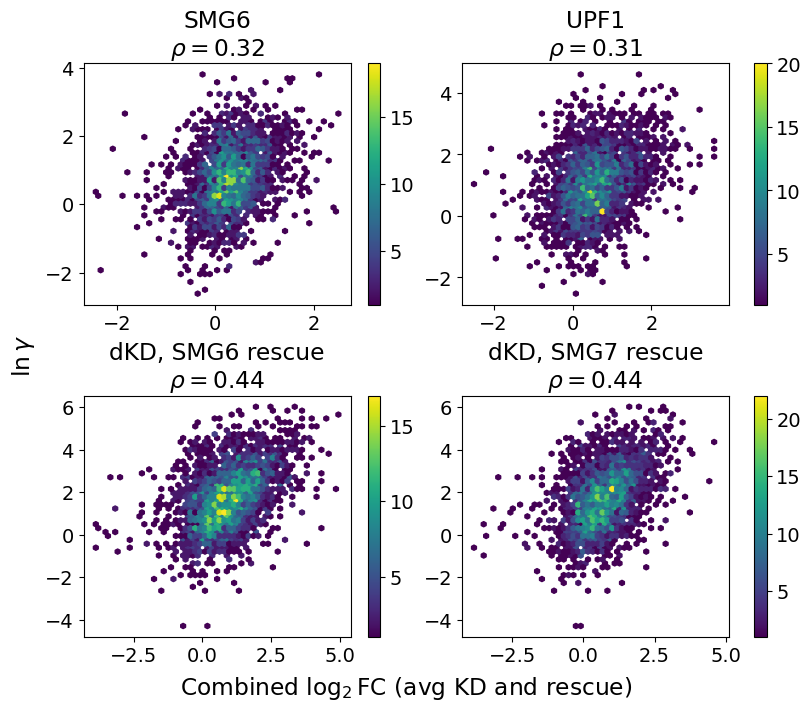

In [193]:
from matplotlib.colors import LogNorm
from scipy.stats import pearsonr,spearmanr

pairs = [('HeLa SMG6 KD', 'HeLa_SMG6_KD', 'SMG6'), 
         ('HeLa UPF1 KD', 'HeLa_UPF1_KD', 'UPF1'),
         ('HeLa dKD', 'HeLa_dKD_smg6', 'dKD, SMG6 rescue'),
         ('HeLa dKD', 'HeLa_dKD_smg7', 'dKD, SMG7 rescue'),
        ]
xlims = [(-2.5,2.6),(-2.5,4),(-4,5),(-4,5)]
f,axes = plt.subplots(2,2,figsize=(8,7),constrained_layout=True)
axes = axes.flatten()
for ax,(our, orig, name),xl in zip(axes,pairs,xlims):
    aa = responder_df[responder_df.experiment==our][['src','event_id','responder','gamma','log_gamma']]
    df = lfc[lfc.kd==orig].reset_index().merge(mapping).merge(aa)
    df = df[(np.isfinite(df.gamma))&(df.logFC>=xl[0])&(df.logFC<=xl[1])]
    #sns.regplot(data=df,x='logFC',y='log_gamma',scatter=False,ax=ax)
    hb = ax.hexbin(
        df.logFC,
        df.log_gamma,
        gridsize=50,
        mincnt=1,
        cmap="viridis",
#        norm=LogNorm(),
    )
    plt.colorbar(hb,ax=ax)
    r,p = spearmanr(df.logFC,df.log_gamma)
    ax.set_title(f'{name}\n'+rf'$\rho={r:.2f}$')
    ax.set_xlabel(None)
    ax.set_ylabel(None)
f.supxlabel(r'Combined $\log_2$FC (avg KD and rescue)')
f.supylabel(r'$\ln \gamma$')

In [194]:
f.savefig('./figures/SF3.pdf',bbox_inches='tight')

### SF4 (intron retention in fractionation experiments)

In [195]:
res = pd.read_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t')

In [196]:
responder_df = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)
responder_df.groupby('experiment').responder.agg('mean')

experiment
HCT116 UPF1 KD     0.680149
HeLa CHX           0.717325
HeLa SMG6 KD       0.800112
HeLa UPF1 KD       0.705121
HeLa dKD           0.691289
HepG2 nucl/cyto    0.736734
K562 nucl/cyto     0.694392
Name: responder, dtype: float64

In [197]:
responder_df = responder_df[~responder_df.experiment.isin(['fractioning_A549','HeLa_SMG7_KD'])].copy()

In [198]:
responder_df.experiment = responder_df.experiment.str.replace('fractioning','frac')
res.experiment = res.experiment.str.replace('fractioning','frac')

In [199]:
responder_df.experiment.unique()

array(['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD',
       'HCT116 UPF1 KD', 'HepG2 nucl/cyto', 'K562 nucl/cyto'],
      dtype=object)

In [200]:
g.__dict__.keys()

dict_keys(['data', 'data2d', 'mask', '_figure', 'row_colors', 'row_color_labels', 'col_colors', 'col_color_labels', 'gs', 'ax_row_dendrogram', 'ax_col_dendrogram', 'ax_row_colors', 'ax_col_colors', 'ax_heatmap', 'ax_cbar', 'cax', 'cbar_pos', 'dendrogram_row', 'dendrogram_col'])

Text(0.0, 1.0, 'B')

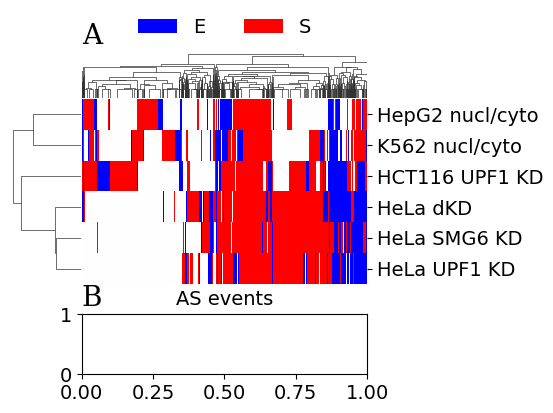

In [201]:
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import linkage

mat = responder_df[responder_df.experiment!='HeLa CHX'].pivot(index=['src', 'event_id'],
                                                              columns='experiment',
                                                              values='responder').replace(0,-1).fillna(0).astype(int)

col_linkage = linkage(
    mat,
    method='average',
    metric='hamming',
    optimal_ordering=True
)

g = sns.clustermap(
    mat.T,
    cmap='bwr',
    xticklabels=False,
    figsize=(6, 3),
    metric='hamming',
    cbar_pos=None,  # отключаем colorbar
    vmin=-1,
    vmax=1,
    col_linkage = col_linkage
)

g.ax_heatmap.set_xlabel('AS events')
g.ax_heatmap.set_ylabel(None)

colors = ['blue','red']
labels = ['E', 'S']

handles = [
    Patch(facecolor=color, label=label)
    for color, label in zip(colors, labels)
]

g.ax_col_dendrogram.legend(
    handles=handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    frameon=False, ncol=2
)

g.ax_col_dendrogram.set_title('A',loc='left',font='serif',fontsize=20)

heatmap_ax = g.ax_heatmap

pos = heatmap_ax.get_position()

# Add an axis below the heatmap
ax_below = g.figure.add_axes([
    pos.x0,       # left
    pos.y0 - 0.3, # bottom
    pos.width,    # width
    0.2          # height
])
ax_below.set_title('B',loc='left',font='serif',fontsize=20)

In [202]:
mat.shape

(6195, 6)

In [203]:
cond = mat.apply(tuple,axis=1)==(-1,-1,-1,-1,1,1,)
frac_specific = mat[cond]

cond = mat[['HeLa SMG6 KD','HeLa UPF1 KD','HeLa dKD']].apply(tuple,axis=1)==(1,-1,-1,)
smg6_specific = mat[cond]

frac_specific = pd.DataFrame(frac_specific.index.tolist(),columns=['src','event_id'])
frac_specific['frac_specific'] = 1
smg6_specific = pd.DataFrame(smg6_specific.index.tolist(),columns=['src','event_id'])
smg6_specific['smg6_specific'] = 1

In [204]:
aa = catalog[['src','event_id','event_type']].merge(frac_specific)
bb = catalog[['src','event_id','event_type']].merge(mat.reset_index()[['src','event_id']].drop_duplicates())

In [205]:
y = bb.event_type.str.contains('IR').mean(),aa.event_type.str.contains('IR').mean()
x = ['All', 'Fractioning-specific']
ax_below.barh(x,y)
ax_below.set_xlabel('Fraction of intron retention events')

Text(0.5, 4.4444444444444375, 'Fraction of intron retention events')

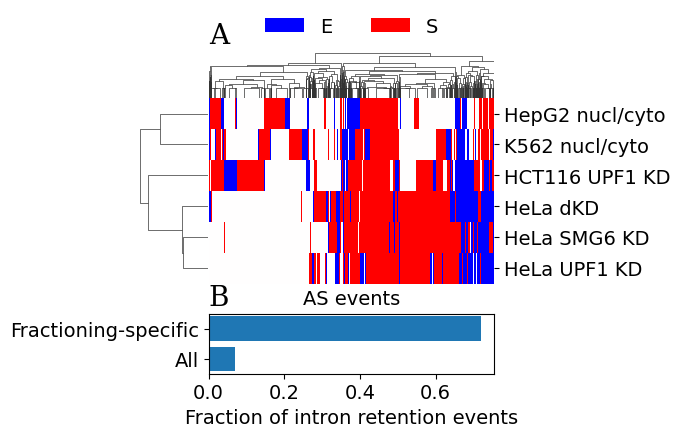

In [206]:
g.figure

In [207]:
g.figure.savefig('./figures/SF4.pdf',bbox_inches='tight')

### SF5 (unclassified 3rd class)

In [208]:
from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
def sample_size(x,y):
    return sum(~((np.isnan(x)|np.isnan(y))))

In [209]:
responder_df = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')

responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

responder_df.groupby('experiment').responder.agg('mean')

responder_df = responder_df[~responder_df.experiment.isin(['fractioning_A549','HeLa_SMG7_KD'])].copy()

responder_df.experiment = responder_df.experiment.str.replace('fractioning','frac')

responder_df.experiment.unique()

array(['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD',
       'HCT116 UPF1 KD', 'HepG2 nucl/cyto', 'K562 nucl/cyto'],
      dtype=object)

In [210]:
mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='prob')

In [211]:
thrs = np.linspace(0.1,0.5,5)
res = []
frac = []
for thr in thrs:
    resp = mat.copy()
    resp = np.where(resp<thr,0,resp)
    resp = np.where(resp>1-thr,1,resp)
    resp = np.where((resp>=thr)&(resp<=1-thr),np.nan,resp)
    
    ssbefore = mat.corr(method=sample_size)
    ssafter = pd.DataFrame(resp).corr(method=sample_size)
    ssafter.index = mat.columns
    ssafter.index.name = None
    ssafter.columns = mat.columns
    ssfrac = ssafter/ssbefore
    
    resp = pd.DataFrame(resp).corr(method=pairwise)
    resp.index = mat.columns
    resp.index.name = None
    resp.columns = mat.columns
    
    long = resp.where(np.triu(np.ones(resp.shape), k=1).astype(bool)).stack().reset_index()
    long.columns = ['e1','e2','f1']
    long['thr'] = thr
    res.append(long)

    sslong = ssfrac.where(np.triu(np.ones(ssfrac.shape), k=1).astype(bool)).stack().reset_index()
    sslong.columns = ['e1','e2','ssfrac']
    sslong['thr'] = thr
    frac.append(sslong)
res = pd.concat(res)
frac = pd.concat(frac)

In [212]:
res['experiment type'] = np.where(res.e1.str.contains('nucl/cyto')==res.e2.str.contains('nucl/cyto'),'same','different')
res.thr = res.thr.round(2)
res.thr = 1-res.thr

frac['experiment type'] = np.where(frac.e1.str.contains('nucl/cyto')==frac.e2.str.contains('nucl/cyto'),'same','different')
frac.thr = frac.thr.round(2)
frac.thr = 1-frac.thr
frac.ssfrac*=100

Text(0, 0.5, '%data remaining')

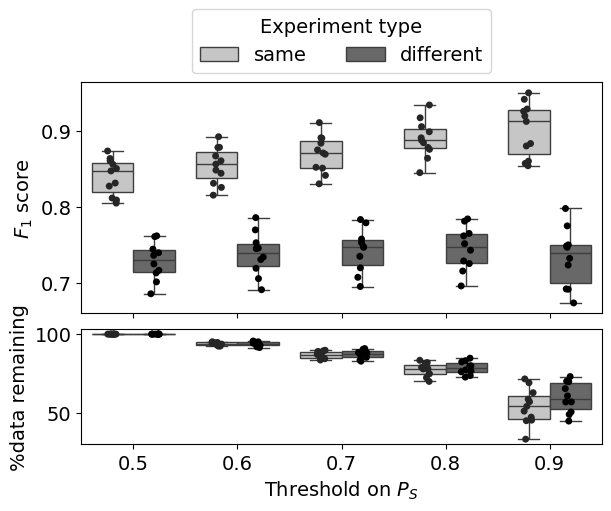

In [213]:
f,(ax,ax2) = plt.subplots(2,figsize=(6,5),constrained_layout=True,sharex=True,height_ratios=(2,1))
sns.boxplot(data=res,x='thr',y='f1',hue='experiment type',palette='Greys',ax=ax)
sns.stripplot(data=res,x='thr',y='f1',hue='experiment type',dodge=True,legend=False,palette='dark:black',ax=ax)
ax.set_xlabel('Threshold on $P_S$')
ax.set_ylabel('$F_1$ score')
ax.legend(ncol=2,loc='lower center',bbox_to_anchor=(0.5,1),title='Experiment type')

sns.boxplot(data=frac,x='thr',y='ssfrac',hue='experiment type',palette='Greys',ax=ax2,legend=False)
sns.stripplot(data=frac,x='thr',y='ssfrac',hue='experiment type',dodge=True,legend=False,palette='dark:black',ax=ax2)
ax2.set_xlabel('Threshold on $P_S$')
ax2.set_ylabel('%data remaining')

In [214]:
f.savefig('./figures/SF5.pdf',bbox_inches='tight')

### SF6 (gamma of selected as events in dKD and HCT116 UPF1 KD)

In [215]:
ctrls = [191508, 191510, 191512]
kds = [191532, 191534, 191536]
meta = pd.DataFrame([[i,'ctrl'] for i in ctrls]+[[i,'exp'] for i in kds],columns=['sample_id','group'])
meta['experiment'] = 'HCT116 UPF1 KD'

dtype = {'src':'category','event_id':"category", 'sample_id':int, 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/pyIPSA/E-MTAB-13788_rnaseq_upf1_kd/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)

data = meta.merge(psi)
data['psi'] = data.num/data.denom
df = data.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
df = df[df.dpsi!=0].copy()


dtype = {'src':'category','event_id':"category", 'sample_id':int, 'num':float, 'denom':float}
ase = pd.read_csv('../../../arkuda_backup/pyIPSA/E-MTAB-13788_rnaseq_upf1_kd/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)

ase = meta.merge(ase)
ase['psi'] = ase.num/ase.denom
ase = ase.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
ase['psi'] = ase.num/ase.denom
ase = ase.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
ase = ase[(ase.denom>15).all(1)].copy()
ase['dpsi'] = ase.psi.exp-ase.psi.ctrl
ase = ase[ase.dpsi!=0].copy()

In [216]:
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

ase.columns = ase.columns.map(d)
ase = ase[d.values()].reset_index()

use = df[(df.ctrl_psi!=0)&(df.exp_psi!=0)]

In [217]:
d = {'RIC8B':'ENSG00000111785_2','PSPC1':'ENSG00000121390_0',
     'NFAT5':'ENSG00000102908_0','U2SURP':'ENSG00000163714_0',
     'RAB5IF':'ENSG00000101084_0','NCSTN':'ENSG00000162736_3'}

aa = pd.DataFrame({'gene_name':d.keys(),'event_id':d.values(),'src':'ensembl'})
aa.merge(df)

,gene_name,event_id,src,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom
0,RIC8B,ENSG00000111785_2,ensembl,HCT116 UPF1 KD,0.009501,0.344887,46.777778,64.111111
1,PSPC1,ENSG00000121390_0,ensembl,HCT116 UPF1 KD,0.199203,0.847477,445.944444,633.055556
2,NFAT5,ENSG00000102908_0,ensembl,HCT116 UPF1 KD,0.387324,0.558209,47.333333,55.833333
3,U2SURP,ENSG00000163714_0,ensembl,HCT116 UPF1 KD,0.003429,0.433613,291.666667,297.500000
4,RAB5IF,ENSG00000101084_0,ensembl,HCT116 UPF1 KD,0.140247,0.360725,875.833333,864.000000
5,NCSTN,ENSG00000162736_3,ensembl,HCT116 UPF1 KD,0.000000,0.050710,265.166667,328.666667


In [218]:
meta2 = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',sep='\t')

dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi2 = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)

data2 = meta2.merge(psi2)
data2['psi'] = data2.num/data2.denom

df = meta2.merge(psi2)
df = df.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
use2 = df[(df.dpsi!=0)].copy()

dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi2 = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)

df = meta2.merge(psi2)
df = df.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
ase2 = df[(df.dpsi!=0)].copy()

In [219]:
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

use2.columns = use2.columns.map(d)
use2 = use2[d.values()].reset_index()

ase2.columns = ase2.columns.map(d)
ase2 = ase2[d.values()].reset_index()

In [220]:
use2 = use2[use2.experiment=='HeLa_dKD']
ase2 = ase2[ase2.experiment=='HeLa_dKD']

In [221]:
use = pd.concat([use,use2])
ase = pd.concat([ase,ase2])

In [222]:
import mm
from importlib import reload
reload(mm)
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\nmd_psi\\helper_functions.py'>

In [223]:
use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)]
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)]

In [224]:
data2 = data2[data2.experiment=='HeLa_dKD']
data = pd.concat([data,data2])

In [225]:
data.experiment = data.experiment.replace('HeLa_dKD','HeLa dKD')

In [226]:
responder_df['gamma'] = hf.psir2gamma(responder_df.ctrl_psi,responder_df.exp_psi)

In [227]:
responder_df[responder_df.event_id=='ENSG00000102908_0']

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,prob,responder,gamma
2062,ensembl,ENSG00000102908_0,HeLa SMG6 KD,0.377129,0.735537,17.125000,20.166667,hela_kd,0.979681,1,4.593548
5591,ensembl,ENSG00000102908_0,HeLa UPF1 KD,0.377129,0.832669,17.125000,41.833333,hela_kd,1.000000,1,8.218740
9354,ensembl,ENSG00000102908_0,HeLa dKD,0.377129,0.870736,17.125000,46.416667,hela_kd,1.000000,1,11.125448
13219,ensembl,ENSG00000102908_0,HCT116 UPF1 KD,0.387324,0.558209,47.333333,55.833333,HCT116_UPF1_KD,0.198609,0,1.998649
16990,ensembl,ENSG00000102908_0,HepG2 nucl/cyto,0.153171,0.618287,96.125000,163.000000,fractioning,0.959559,1,8.955126
19958,ensembl,ENSG00000102908_0,K562 nucl/cyto,0.190451,0.583016,66.100000,92.312500,fractioning,0.979458,1,5.943186


C:\Users\zavil\AppData\Local\Temp\ipykernel_22372\2748997396.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.groupby(['gene_name', 'group'])[['num', 'denom']]
C:\Users\zavil\AppData\Local\Temp\ipykernel_22372\2748997396.py:94: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(
C:\Users\zavil\AppData\Local\Temp\ipykernel_22372\2748997396.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.groupby(['gene_name', 'group'])[['num', 'denom']]
C:\Users\zavil\AppData\Local\Temp\ipykernel_22372\2748997396.py:9

Text(0, 0.5, '')

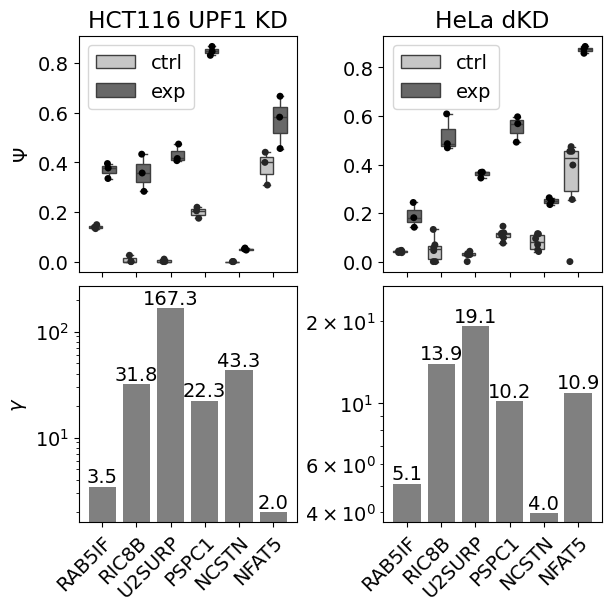

In [228]:
tmp = aa.merge(data)

order = ['RAB5IF', 'RIC8B', 'U2SURP', 'PSPC1', 'NCSTN', 'NFAT5']
tmp.gene_name = (
    tmp.gene_name.astype('category')
    .cat.reorder_categories(order)
)
tmp = tmp.sort_values(['experiment', 'gene_name', 'group'])

experiments = tmp['experiment'].unique()

fig, axes = plt.subplots(
    2, 2,
    figsize=(6, 6),
    sharex='col',
    constrained_layout=True
)

for j, experiment in enumerate(experiments):

    d = tmp[tmp['experiment'] == experiment]

    ax = axes[0, j]
    ax2 = axes[1, j]

    # --- Верхняя панель ---
    sns.boxplot(
        data=d,
        x='gene_name',
        y='psi',
        hue='group',
        palette='Greys',
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=d,
        x='gene_name',
        y='psi',
        hue='group',
        palette='dark:black',
        dodge=True,
        legend=False,
        ax=ax
    )

    ax.legend(title=None)
    ax.set_xlabel(None)
    ax.set_ylabel(r"$\Psi$")

    # Заголовок experiment только на верхней панели
    ax.set_title(str(experiment))

    # --- Нижняя панель ---
    bb = (
        d.groupby(['gene_name', 'group'])[['num', 'denom']]
        .agg('sum')
    )

    bb = (
        ((bb.num + 1) / (bb.denom + 1))
        .reset_index()
        .pivot(
            index='gene_name',
            columns='group',
            values=0
        )
    )

    gamma = hf.psir2gamma(bb.ctrl, bb.exp)
    gamma = gamma.reindex(order)

    ax2.bar(gamma.index, gamma, color='grey')
    ax2.set_yscale('log')
    ax2.set_ylabel(r'$\gamma$')

    # Подписи над столбцами
    for x, y in gamma.items():
        ax2.annotate(
            f'{y:.1f}',
            xy=(x, y),
            xytext=(0, 0),
            textcoords='offset points',
            ha='center',
            va='bottom'
        )

    # Место для подписей над столбцами
    ymin, ymax = ax2.get_ylim()
    ax2.set_ylim(ymin, ymax * 1.3)

    # Поворот названий генов
    ax2.set_xticklabels(
        ax2.get_xticklabels(),
        rotation=45,
        rotation_mode='anchor',
        ha='right'
    )

# Общий вид
axes[0, 0].set_ylabel(r"$\Psi$")
axes[0, 1].set_ylabel(None)
axes[1, 1].set_ylabel(None)

In [229]:
fig.savefig('./figures/SF6.pdf',bbox_inches='tight')